<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-13/lab-077-hamiltonian-learning.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 077. Hamiltonian learning

A quantum simulator is built to realise a chosen type of interaction between its qubits, for instance nearest-neighbour exchange in a chain. The strengths of the couplings and fields are set by drifting calibrations and device imperfections, so the Hamiltonian that drives the qubits is known in its form and unknown in its numbers. The device cannot be opened and returns only bit strings. We prepare known product states, let them evolve for a chosen time, measure every qubit in a chosen basis and repeat. From these bit strings we infer the coefficients of the Hamiltonian, a task called Hamiltonian learning. It extends learning a state from measurements to learning the law that moves every state.

The running model is an anisotropic Heisenberg chain of four qubits with two uniform fields, whose five coefficients are the unknowns. We are given the list of Pauli terms in the Hamiltonian and three product states that the device prepares on demand. The device evolves them for a chosen time and measures all qubits in the $Z$, $X$ or $Y$ basis, with $M$ shots for every combination of initial state, time and basis. We simulate the device to produce the data, write a differentiable model of the same experiment, and fit the coefficients by minimising the negative log-likelihood of the measured bit strings with gradients from automatic differentiation. We then determine which coefficients the data fix, how the error falls with the number of shots and which bound limits it, and apply the same method to the decay and dephasing rates of an open qubit. We call a fit successful when the estimated coefficients differ from the true ones by less than ten percent in the relative error of equation (7).

Sections 2 and 3 define the model and simulate the experiment, Section 4 introduces the likelihood and Section 5 fits the coefficients. Section 6 shows a pair of Hamiltonians that data in real bases cannot distinguish, Section 7 measures the error against the number of shots and Section 8 compares it with the Cramér–Rao bound. Section 9 learns the rates of a Lindblad equation. Sections 1 to 9 form the core route. Sections 10 and 11 are for work at home. Section 10 measures how often a fit from a single random start succeeds, for the chain above and for the PXP model of Rydberg atoms, and in our runs it fails in most problems of both models. Section 11 shows how a neural differential equation in the form of Ref. [1] repairs the fit of the PXP model and absorbs a term missing from the model. It reimplements the method of Ref. [1] at a smaller scale, with three global measurement bases in place of 200 random Pauli bases, at most six qubits and our own network and training lengths.

Quantities labelled exact come from the simulated state vector or density matrix, known to the simulation and unknown to an experimenter. Quantities labelled estimated come from simulated bit strings with fixed random seeds, in the form a device returns them. The true coefficients enter only the simulation of the device and the final comparison, never a loss function.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, so that identities hold to about $10^{-12}$. JAX builds the forward model, differentiates the likelihood and draws the random shots on the CPU [2], SciPy provides a reference matrix exponential, and Matplotlib draws the figures. The cells run in order.

Besides `jax.grad`, `jax.jit`, `jax.vmap` and the random keys of the earlier labs, the code uses five further JAX tools. The function `jax.lax.scan` is a loop that JAX can compile and differentiate. It applies a step function repeatedly to a carried state and returns the final state together with the stack of the values that the step function emitted along the way. We use it for the time steps of the evolution and for the steps of the optimiser. A pytree is a nested Python container of arrays, such as a tuple or a dictionary, and `jax.tree_util.tree_map` applies a function to every array in it, so one optimiser serves a vector of coefficients and the weights of a network alike. The function `jax.value_and_grad` returns the loss and its gradient from one evaluation. The function `jax.jacfwd` returns the matrix of all derivatives of a vector-valued function, here of every probability with respect to every coefficient, by forward-mode differentiation. The sampler `jax.random.multinomial` draws the counts of all outcomes for a given number of shots and given probabilities.

On a laptop CPU the core route, Sections 1 to 9, takes about one minute. The cells for work at home are marked where they occur. The success rates of Section 10 take about three minutes, most of it for the PXP model with six atoms. Section 11.1 takes about 45 s, and each of the two cells of Section 11.2 takes about 20 s. The whole notebook takes about five minutes. The last code cell prints the numbers and the runtime, and it also runs directly after the core route.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # small calculations; the CPU avoids GPU memory allocation
import json, time
from functools import partial
from pathlib import Path
import numpy as np
import scipy.linalg
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
# course palette: model orange, data sky blue, exact black, failures grey; one colour per coefficient
COL = dict(model="#D35A05", data="#3E8FD0", exact="black", grey="#5A6270", rand="#9AA0A6", navy="#002B5C",
           blue="#005CA7", green="#1B7F36")
COL.update(purple="#6A3D9A", teal="#1B9E77", brown="#8C564B", magenta="#C51B7D")
# non-estimator series (coefficients, directions, model variants) use navy, purple, teal, brown, magenta
COEF_COL = [COL["navy"], COL["purple"], COL["teal"], COL["brown"], COL["magenta"]]
COEF_LABEL = {"Jx": r"$J_x$", "Jy": r"$J_y$", "Jz": r"$J_z$", "hx": r"$h_x$", "hz": r"$h_z$"}
# the helpers from here to `sci` save figures and numbers for the lecture notes and can be skipped on a first reading
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)

def _rc(size):
    return {"font.size": size, "axes.labelsize": size, "xtick.labelsize": size, "ytick.labelsize": size, "legend.fontsize": size}

def figure_set(name, panels, label_xy):
    # notes: all panels side by side, 7.0 x 2.9 in, 11 pt, labelled (a), (b), ...
    # slides: one file per panel, <name>_a, <name>_b, ..., 4.6 x 3.1 in, 12.5 pt
    for i, draw in enumerate(panels):
        with plt.rc_context(_rc(12.5)):
            fig, ax = plt.subplots(figsize=(4.6, 3.1)); draw(ax); save(fig, f"{name}_{'abcd'[i]}"); plt.close(fig)
    with plt.rc_context(_rc(11)):
        fig, axes = plt.subplots(1, len(panels), figsize=(7.0, 2.9))
        for i, (draw, ax) in enumerate(zip(panels, axes)):
            draw(ax); ax.text(*label_xy[i], f"({'abcd'[i]})", transform=ax.transAxes)
        fig.tight_layout(); save(fig, name)
    plt.show()

def figure_single(name, draw):
    # one panel, 4.6 x 3.1 in, 12 pt, used in notes and slides
    with plt.rc_context(_rc(12)):
        fig, ax = plt.subplots(figsize=(4.6, 3.1)); draw(ax); fig.tight_layout(); save(fig, name)
    plt.show()
started = time.perf_counter()
NUMBERS = {}
def sci(x, digits=1):
    # LaTeX form of a number in scientific notation for the macro file, e.g. 1.1\times10^{5} (used in math mode)
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
key = jax.random.PRNGKey(77)
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. The model and its unknown coefficients

The device is a chain of $N=4$ qubits with open ends. Its Hamiltonian is assumed to be an anisotropic Heisenberg (XYZ) chain in two uniform fields,
$$\hat{\mathcal H}(\boldsymbol\theta)=\sum_{i=0}^{N-2}\big(J_x\hat X_i\hat X_{i+1}+J_y\hat Y_i\hat Y_{i+1}+J_z\hat Z_i\hat Z_{i+1}\big)+\sum_{i=0}^{N-1}\big(h_x\hat X_i+h_z\hat Z_i\big) , \tag{1}$$
where $\hat X_i$, $\hat Y_i$ and $\hat Z_i$ are the Pauli matrices of qubit $i$. The exchange couplings $J_x$, $J_y$ and $J_z$ set how strongly neighbouring spins prefer to be aligned or anti-aligned along each axis, and the fields $h_x$ and $h_z$ turn every spin towards the $x$ and $z$ axes. Which Pauli strings appear in equation (1) is known from the design of the device. The five coefficients $\boldsymbol\theta=(J_x,J_y,J_z,h_x,h_z)$ are the unknowns to be learned. We set $\hbar=1$, so energies are frequencies and times are measured in units of the inverse coupling.

Every coefficient multiplies a fixed matrix, $\hat{\mathcal H}(\boldsymbol\theta)=\sum_j\theta_j\hat P_j$, where $\hat P_j$ is the sum of Pauli strings that belongs to coefficient $j$. The code stores them in a dictionary keyed by coefficient name, so every printed number carries its name. The sketch shows the experiment, with the evolution box hiding the unknown numbers.

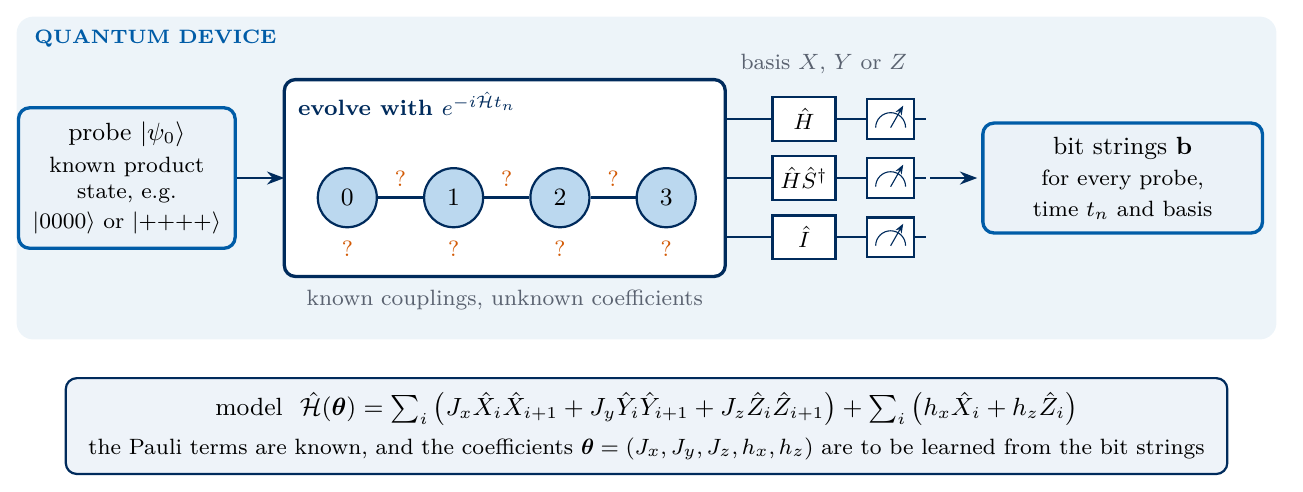

*Hamiltonian learning with a known structure. Known product states evolve for a time $t_n$ under the unknown Hamiltonian, every qubit is rotated into the $X$, $Y$ or $Z$ basis and measured, and the bit strings are the only output.*

The matrices are built as Kronecker products with qubit 0 as the leftmost factor, so the amplitude of the bit string $b_0b_1\dots b_{N-1}$ sits at index $\sum_qb_q2^{N-1-q}$. The true values of the simulated device are $J_x=1$, $J_y=0.6$, $J_z=0.3$, $h_x=0.5$ and $h_z=0.2$.

In [2]:
N = 4
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
HAD = (X + Z) / np.sqrt(2)                       # Hadamard gate
S_DAG = np.diag([1, -1j])                        # inverse phase gate

def op(n, factors):
    # Kronecker product over qubits 0..n-1 (qubit 0 leftmost); factors = {qubit: 2x2 matrix}
    out = np.eye(1, dtype=complex)
    for q in range(n):
        out = np.kron(out, factors.get(q, I2))
    return out

def xyz_terms(n):
    # the five matrices P_j of equation (1), keyed by the name of their coefficient
    return {"Jx": sum(op(n, {i: X, i + 1: X}) for i in range(n - 1)),
            "Jy": sum(op(n, {i: Y, i + 1: Y}) for i in range(n - 1)),
            "Jz": sum(op(n, {i: Z, i + 1: Z}) for i in range(n - 1)),
            "hx": sum(op(n, {i: X}) for i in range(n)),
            "hz": sum(op(n, {i: Z}) for i in range(n))}

TERMS = xyz_terms(N)
NAMES = list(TERMS)                               # ["Jx", "Jy", "Jz", "hx", "hz"]
P_STACK = jnp.asarray(np.array([TERMS[k] for k in NAMES]))
THETA_TRUE = {"Jx": 1.0, "Jy": 0.6, "Jz": 0.3, "hx": 0.5, "hz": 0.2}
theta_true = jnp.array([THETA_TRUE[k] for k in NAMES])

def hamiltonian(theta, P=P_STACK):
    return jnp.tensordot(theta.astype(complex), P, axes=1)

def named(theta, names=NAMES):
    return {k: round(float(v), 4) for k, v in zip(names, np.asarray(theta))}

H_true = np.asarray(hamiltonian(theta_true))
assert np.allclose(H_true, H_true.conj().T, atol=TOL)                      # Hermitian
assert all(np.allclose(TERMS[k].imag, 0) for k in NAMES)                   # every P_j is a real matrix (used in Section 6)
ket0000 = np.zeros(2 ** N, dtype=complex); ket0000[0] = 1
assert np.allclose(op(N, {0: X}) @ ket0000, np.eye(2 ** N)[8])            # X on qubit 0 flips the most significant bit
print("coefficients:", NAMES)
print("true values :", THETA_TRUE)
print(f"Hamiltonian: {H_true.shape[0]} x {H_true.shape[1]}, eigenvalues from {np.linalg.eigvalsh(H_true).min():.3f} to {np.linalg.eigvalsh(H_true).max():.3f}")

coefficients: ['Jx', 'Jy', 'Jz', 'hx', 'hz']
true values : {'Jx': 1.0, 'Jy': 0.6, 'Jz': 0.3, 'hx': 0.5, 'hz': 0.2}
Hamiltonian: 16 x 16, eigenvalues from -4.186 to 5.112


## 3. The simulated experiment

An experiment prepares a known initial state $|\psi_0\rangle$, called a probe, lets it evolve for a time $t$ and measures. The state at time $t$ is
$$|\psi_{\boldsymbol\theta}(t)\rangle=e^{-i\hat{\mathcal H}(\boldsymbol\theta)t}|\psi_0\rangle . \tag{2}$$
We use three probes that are easy to prepare, $|0000\rangle$, the Néel state $|0101\rangle$ and $|{+}{+}{+}{+}\rangle$ with $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$, and the six times $t_n=n\,\Delta t$ with $\Delta t=0.25$ and $n=1,\dots,6$. The evolution operator over one interval, $\hat U(\Delta t)=e^{-i\hat{\mathcal H}\Delta t}$, is computed once and applied $n$ times. We evaluate the exponential with the scaling-and-squaring method [3], which divides the matrix by $2^s$, sums the Taylor series to order $m_{\max}$ and squares the result $s$ times,
$$e^{\hat A}\approx\Big[\sum_{m=0}^{m_{\max}}\frac{1}{m!}\Big(\frac{\hat A}{2^s}\Big)^m\Big]^{2^s} , \tag{3}$$
with $s=6$ and $m_{\max}=12$. Equation (3) consists of matrix products, so JAX differentiates through it, and the code checks it against the matrix exponential of SciPy.

All qubits are measured in the same basis $g\in\{Z,X,Y\}$. The device measures in the computational basis, so a measurement in the $X$ basis applies a Hadamard gate $\hat H$ to every qubit first, and a measurement in the $Y$ basis applies $\hat S^\dagger$ and then $\hat H$. Bit 0 records the eigenvalue $+1$ of the measured Pauli matrix. By the Born rule the probability of the bit string $\mathbf b$ is
$$p_{\boldsymbol\theta}(\mathbf b\,|\,c)=\big|\langle\mathbf b|\hat U_g|\psi_{\boldsymbol\theta}(t_n)\rangle\big|^2,\qquad \hat U_Z=\hat I,\quad\hat U_X=\hat H^{\otimes N},\quad\hat U_Y=(\hat H\hat S^\dagger)^{\otimes N} , \tag{4}$$
where $c=(\psi_0,g,t_n)$ labels one configuration of probe, basis and time. There are $3\times3\times6=54$ configurations, and the device returns $M=1000$ bit strings for each. We store the record as counts $n_c(\mathbf b)$, the number of times the string $\mathbf b$ appeared in configuration $c$, which hold all its information because the shots are independent.

In [3]:
def expm_taylor(A, s=6, order=12):
    # equation (3): scaling and squaring of the Taylor series; differentiable by jax.grad
    B = A / 2 ** s
    out = term = jnp.eye(A.shape[0], dtype=A.dtype)
    for m in range(1, order + 1):
        term = term @ B / m
        out = out + term
    for _ in range(s):
        out = out @ out
    return out

def product_state(single_qubit_states):
    out = np.ones(1, dtype=complex)
    for v in single_qubit_states:
        out = np.kron(out, v)
    return out

k0, k1 = np.array([1, 0], complex), np.array([0, 1], complex)
kp = np.array([1, 1], complex) / np.sqrt(2)
PROBE_NAMES = ["|0000>", "|0101>", "|++++>"]
PROBES = jnp.asarray(np.array([product_state([k0] * 4), product_state([k0, k1, k0, k1]), product_state([kp] * 4)]))
BASIS_NAMES = ["Z", "X", "Y"]
def basis_rotations(n):
    # U_g of equation (4) for g = Z, X, Y on all n qubits
    return jnp.asarray(np.array([np.eye(2 ** n), op(n, {q: HAD for q in range(n)}), op(n, {q: HAD @ S_DAG for q in range(n)})]))
U_BASES = basis_rotations(N)
DT, K_TIMES = 0.25, 6
TIMES = DT * np.arange(1, K_TIMES + 1)

def make_born(P, probes, u_bases, dt, k_times):
    # returns theta -> probabilities p[probe, basis, time, b] of equation (4)
    def born(theta):
        U = expm_taylor(-1j * dt * hamiltonian(theta, P))
        def step(psi, _):
            psi = psi @ U.T                     # one interval for every probe at once
            return psi, psi
        # jax.lax.scan: a loop over the time steps that JAX can compile and differentiate; it returns the final state
        # and the stack of the states emitted by `step`, here traj[time, probe, amplitude]
        _, traj = jax.lax.scan(step, probes, None, length=k_times)
        amp = jnp.einsum("gab,kpb->pgka", u_bases, traj)
        return jnp.abs(amp) ** 2
    return born

born = jax.jit(make_born(P_STACK, PROBES, U_BASES, DT, K_TIMES))

@jax.jit
def sample_counts(key, p, shots):
    # counts n_c(b) of `shots` independent bit strings for every configuration c (multinomial draw per configuration)
    return jax.random.multinomial(key, 1.0 * shots, p / p.sum(-1, keepdims=True))

A_test = -1j * 0.7 * H_true
assert np.allclose(expm_taylor(jnp.asarray(A_test)), scipy.linalg.expm(A_test), atol=1e-12)
p_true = born(theta_true)
assert np.allclose(p_true.sum(-1), 1, atol=TOL)
psi_check = scipy.linalg.expm(-1j * H_true * TIMES[3]) @ np.asarray(PROBES[1])
assert np.allclose(np.abs(np.asarray(U_BASES[2]) @ psi_check) ** 2, p_true[1, 2, 3], atol=1e-12)
M_MAIN = 1000
key, k = jax.random.split(key)
counts = sample_counts(k, p_true, M_MAIN)
assert int(counts.sum()) == 54 * M_MAIN
idx0 = np.flatnonzero(np.asarray(counts[1, 0, 0]))[:4]
print("configurations:", counts.shape[:3], "(probe, basis, time) with", M_MAIN, "shots each")
print("probe |0101>, Z basis, t = 0.25, first nonzero counts:",
      {format(int(i), "04b"): int(counts[1, 0, 0, i]) for i in idx0})

configurations: (3, 3, 6) (probe, basis, time) with 1000 shots each
probe |0101>, Z basis, t = 0.25, first nonzero counts: {'0000': 3, '0001': 16, '0010': 4, '0011': 106}


In one shot of the $Z$ basis the value of $\hat Z_i$ is $(-1)^{b_i}$, and the same rule gives $\hat X_i$ in the $X$ basis and $\hat Y_i$ in the $Y$ basis, so the bit strings determine every Pauli expectation value their basis measures. The figure shows the mean magnetisations $m_g(t)=\frac1N\sum_i\langle\hat\sigma^g_i\rangle$, with $\hat\sigma^g=\hat Z,\hat X,\hat Y$, for the probe $|0000\rangle$, estimated from the 1000 shots at each of the six times and computed exactly on a fine time grid. The likelihood below uses the full bit strings with all their correlations, so the magnetisations show only part of the information.

m_z, m_x, m_y at t = 1.5 from bit strings: [ 0.291 -0.172 -0.184]  exact: [ 0.31  -0.154 -0.191]


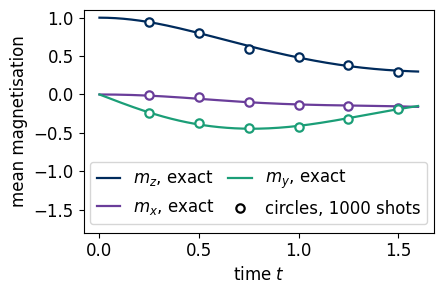

In [4]:
SIGN = (-1.0) ** ((np.arange(2 ** N)[:, None] >> (N - 1 - np.arange(N))[None, :]) & 1)   # SIGN[b, i] = (-1)^{b_i}
def magnetisation_from_counts(c):
    return np.asarray(c) @ SIGN.mean(axis=1) / np.asarray(c).sum(-1)

t_fine = np.linspace(0, 1.6, 161)
U_np = np.asarray(U_BASES)
def exact_magnetisations(H, psi0, times):
    out = []
    for t in times:
        psi = scipy.linalg.expm(-1j * H * t) @ psi0
        out.append([np.abs(U_np[g] @ psi) ** 2 @ SIGN.mean(axis=1) for g in range(3)])
    return np.array(out)

m_exact = exact_magnetisations(H_true, np.asarray(PROBES[0]), t_fine)
m_data = magnetisation_from_counts(counts[0])                  # [basis, time]
m_err = np.sqrt(np.maximum(1 - m_data ** 2, 0) / (N * M_MAIN))  # rough error bar, ignoring correlations between qubits
def draw_data(ax):
    for g, (lab, col) in enumerate(zip([r"$m_z$", r"$m_x$", r"$m_y$"], [COL["navy"], COL["purple"], COL["teal"]])):
        ax.plot(t_fine, m_exact[:, g], "-", color=col, lw=1.6, label=lab + ", exact")
        ax.errorbar(TIMES, m_data[g], yerr=m_err[g], fmt="o", color=col, ms=6, mfc="white", mew=1.6, capsize=2)
    ax.plot([], [], "o", color=COL["exact"], mfc="white", mew=1.6, label="circles, 1000 shots")
    ax.set_xlabel(r"time $t$"); ax.set_ylabel("mean magnetisation")
    ax.set_ylim(-1.8, 1.1); ax.legend(loc="lower center", ncol=2, columnspacing=0.8, handlelength=1.4)
figure_single("fig_lab077_data", draw_data)
print("m_z, m_x, m_y at t = 1.5 from bit strings:", np.round(m_data[:, -1], 3), " exact:", np.round(exact_magnetisations(H_true, np.asarray(PROBES[0]), [1.5])[0], 3))

All spins of the probe $|0000\rangle$ start along $+z$, so $m_z=1$ and $m_x=m_y=0$ at $t=0$. The field $h_x$ rotates every spin about the $x$ axis and turns $m_z$ into a negative $m_y$, initially at the rate $dm_y/dt=-2h_x$, and the exchange couplings then reduce and dephase the magnetisation. The open circles, estimated from 1000 shots per time and basis, scatter around the exact curves by about $1/\sqrt{NM}$, the statistical error of a mean of $\pm1$ values. The likelihood combines the information that each time and basis carries about the five coefficients.

## 4. The likelihood of the bit strings

A candidate $\boldsymbol\theta$ predicts, through equations (2) and (4), the probability of every bit string in every configuration. The shots are independent, so the probability of the record is the product over all shots. Its negative logarithm, divided by the total number of shots $M_{\mathrm{tot}}=\sum_c\sum_{\mathbf b}n_c(\mathbf b)$, is the loss
$$\mathcal L(\boldsymbol\theta)=-\frac{1}{M_{\mathrm{tot}}}\sum_c\sum_{\mathbf b}n_c(\mathbf b)\,\ln p_{\boldsymbol\theta}(\mathbf b\,|\,c) , \tag{5}$$
the negative log-likelihood (NLL) per shot, in nats. Minimising it gives the maximum-likelihood estimate $\tilde{\boldsymbol\theta}$. The loss contains only the counts delivered by a device and the model probabilities, never the true state or the true coefficients, so it can be evaluated on real data. The sketch shows the chain from $\boldsymbol\theta$ to the loss.

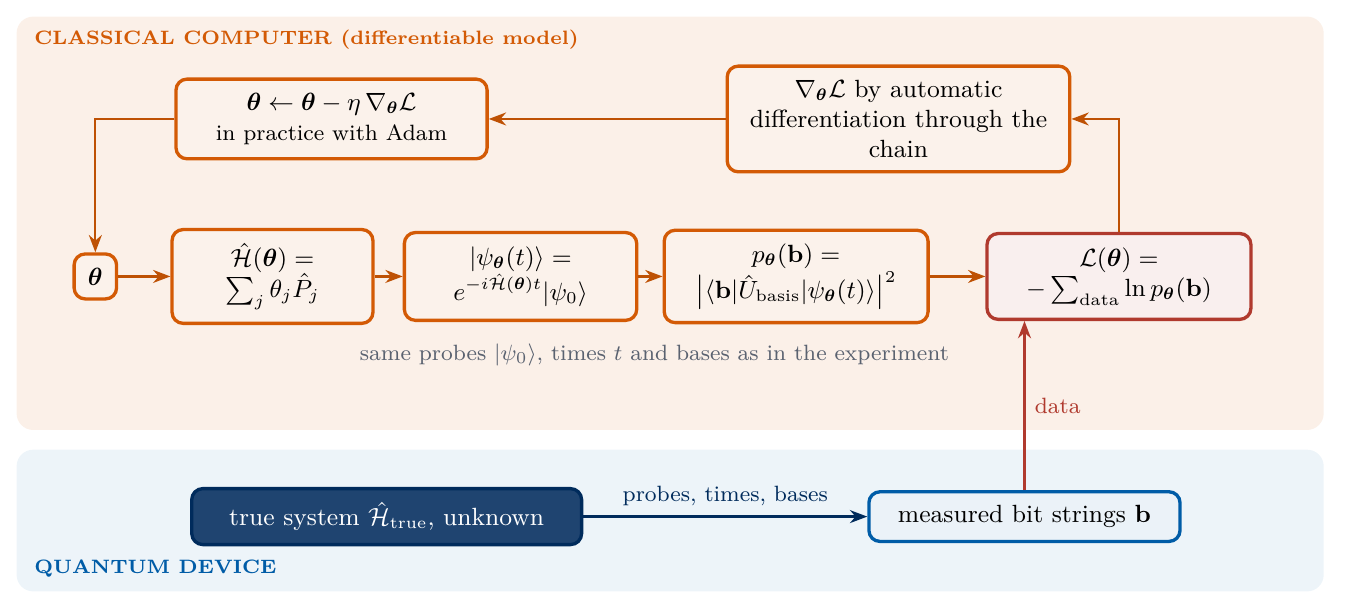

*Forward model and training loop. The coefficients define the Hamiltonian, which evolves the probe, the Born rule gives the probabilities of the measured strings, and automatic differentiation through the chain gives the gradient of the loss.*

Every step of the chain is differentiable, so `jax.grad` returns $\nabla_{\boldsymbol\theta}\mathcal L$ exactly, and the code checks one component against a central finite difference. The loss is then minimised by gradient descent,
$$\boldsymbol\theta\leftarrow\boldsymbol\theta-\eta\,\nabla_{\boldsymbol\theta}\mathcal L(\boldsymbol\theta) , \tag{6}$$
with a step size $\eta$. In practice we use the Adam optimiser [4], a variant of equation (6) that rescales the step of each coefficient by running averages of its past gradients and their squares. The code writes out its few lines with the standard averaging constants of Ref. [4].

In [5]:
def make_nll(born_fn):
    def nll(theta, c):
        # equation (5): negative log-likelihood per shot
        return -jnp.sum(c * jnp.log(born_fn(theta) + 1e-300)) / jnp.sum(c)
    return nll

nll = jax.jit(make_nll(born))
grad_nll = jax.jit(jax.grad(make_nll(born)))
grad0 = grad_nll(theta_true, counts)
eps = 1e-6; e2 = jnp.zeros(5).at[2].set(eps)
fd = (nll(theta_true + e2, counts) - nll(theta_true - e2, counts)) / (2 * eps)
assert abs(float(grad0[2]) - float(fd)) < 1e-7
print("gradient of the NLL at the true coefficients:", named(grad0))
print(f"d L / d Jz: jax.grad {float(grad0[2]):.8f}, central difference {float(fd):.8f}")

tmap = jax.tree_util.tree_map
def adam(loss, params, lr, steps, b1=0.9, b2=0.999, eps=1e-8, record=None):
    # Adam [4] on any pytree of parameters; lr is a number or a pytree of step sizes with the same structure.
    # Returns the final parameters and the loss before every step. With record = a function of the parameters,
    # the second output is the stack of record(parameters) after every step, used to draw the path of a fit.
    lrs = tmap(lambda p: lr, params) if np.isscalar(lr) else lr
    value_and_grad = jax.value_and_grad(loss)
    def step(carry, t):
        p, m, v = carry
        L, gr = value_and_grad(p)
        m = tmap(lambda a, b: b1 * a + (1 - b1) * b, m, gr)          # running average of the gradient
        v = tmap(lambda a, b: b2 * a + (1 - b2) * b ** 2, v, gr)     # running average of its square
        p = tmap(lambda q, a, b, r: q - r * (a / (1 - b1 ** (t + 1))) / (jnp.sqrt(b / (1 - b2 ** (t + 1))) + eps), p, m, v, lrs)
        return (p, m, v), (L if record is None else record(p))
    zeros = tmap(jnp.zeros_like, params)
    # scan carries the parameters and the two running averages from step to step and stacks the output of every step
    (p, _, _), history = jax.lax.scan(step, (params, zeros, zeros), jnp.arange(steps))
    return p, history

gradient of the NLL at the true coefficients: {'Jx': 0.02, 'Jy': 0.0002, 'Jz': -0.0007, 'hx': -0.0004, 'hz': -0.0067}
d L / d Jz: jax.grad -0.00065002, central difference -0.00065002


The gradient at the true coefficients is small but nonzero, because for a finite record the maximum of the likelihood lies close to the true values without coinciding with them.

## 5. Fitting the coefficients

We start the fit from random coefficients drawn uniformly from $[-1,1]$, run 1000 Adam steps with step size $0.05$, and measure the result by the relative error
$$\epsilon(\tilde{\boldsymbol\theta})=\frac{\sum_j|\tilde\theta_j-\theta_j|}{\sum_j|\theta_j|} , \tag{7}$$
which only a simulation can compute. We call a fit successful when $\epsilon<0.1$, the criterion of Ref. [1]. The loss of equation (5) is not convex, and a single start can end in a local minimum, a point where the gradient vanishes and the loss is higher than at the global minimum. We therefore run twelve independent starts in parallel and keep the one with the lowest final loss. This choice uses only the data and is therefore available in a real experiment. The figure shows the coefficients during the best run and the final loss of every start, and the cell prints the coefficients at which the unsuccessful starts end.

12 starts x 1000 Adam steps in 4.4 s
final NLL per start   : [2.2598 2.1858 2.6505 2.7578 2.797  2.1858 2.397  2.3682 2.2421 2.1858
 2.3946 2.5367]
relative error / start: [1.577 0.005 0.614 1.785 1.135 0.005 0.532 1.682 1.607 0.005 1.855 2.161]
lowest NLL: start 5, L = 2.18581 (NLL of the true coefficients 2.18589)
estimate: {'Jx': 0.9931, 'Jy': 0.5993, 'Jz': 0.2982, 'hx': 0.5004, 'hz': 0.2028}
truth   : {'Jx': 1.0, 'Jy': 0.6, 'Jz': 0.3, 'hx': 0.5, 'hz': 0.2} | relative error 0.0049
starts within 10 % of the truth: 3 of 12
coefficients (Jx, Jy, Jz, hx, hz) at the end of the unsuccessful starts:
  start  0: [-0.98 -0.56 -0.46  0.45  0.04], NLL 2.2598
  start  2: [ 0.7   0.8   0.37 -0.2  -0.13], NLL 2.6505
  start  3: [-0.98  0.06  0.71 -0.89  0.53], NLL 2.7578
  start  4: [ 0.91 -0.71 -0.22  1.24 -0.09], NLL 2.7970
  start  6: [0.62 0.85 0.9  0.47 0.07], NLL 2.3970
  start  7: [-0.59 -0.82 -0.98  0.51  0.12], NLL 2.3682
  start  8: [-1.01 -0.53 -0.41  0.46 -0.1 ], NLL 2.2421
  start 10

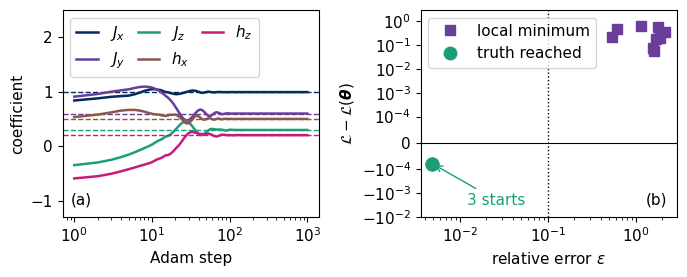

In [6]:
N_STARTS, FIT_STEPS = 12, 1000
fit_one = lambda th0, c: adam(lambda th: make_nll(born)(th, c), th0, 0.05, FIT_STEPS)
fit_many = jax.jit(jax.vmap(fit_one, in_axes=(0, None)))

def rel_error(theta_est, theta_ref):
    return np.abs(np.asarray(theta_est) - np.asarray(theta_ref)).sum(-1) / np.abs(np.asarray(theta_ref)).sum()   # equation (7)

t0 = time.perf_counter()
key, k = jax.random.split(key)
starts = jax.random.uniform(k, (N_STARTS, 5), minval=-1, maxval=1)
theta_fits, histories = fit_many(starts, counts)
theta_fits, histories = np.asarray(theta_fits), np.asarray(histories)
t_fit = time.perf_counter() - t0
final_L = histories[:, -1]
errors_starts = rel_error(theta_fits, theta_true)
best = int(np.argmin(final_L))
theta_tilde = jnp.asarray(theta_fits[best])
L_true = float(nll(theta_true, counts))
assert final_L[best] <= L_true + 1e-9                       # the maximum-likelihood estimate fits the data at least as well as the truth
assert errors_starts[best] < 0.05
n_success = int(np.sum(errors_starts < 0.1))
print(f"{N_STARTS} starts x {FIT_STEPS} Adam steps in {t_fit:.1f} s")
print("final NLL per start   :", np.round(final_L, 4))
print("relative error / start:", np.round(errors_starts, 3))
print(f"lowest NLL: start {best}, L = {final_L[best]:.5f} (NLL of the true coefficients {L_true:.5f})")
print("estimate:", named(theta_tilde))
print("truth   :", THETA_TRUE, f"| relative error {errors_starts[best]:.4f}")
print(f"starts within 10 % of the truth: {n_success} of {N_STARTS}")
NUMBERS.update(Starts=f"{N_STARTS}", FitSteps=f"{FIT_STEPS}", StartsGood=f"{n_success}", BestErr=f"{errors_starts[best]:.3f}",
               **{f"Est{k_.capitalize()}": f"{float(v):.3f}" for k_, v in zip(NAMES, theta_tilde)})

print("coefficients (Jx, Jy, Jz, hx, hz) at the end of the unsuccessful starts:")
for i_ in np.flatnonzero(errors_starts >= 0.1):
    print(f"  start {i_:2d}: {np.round(theta_fits[i_], 2)}, NLL {final_L[i_]:.4f}")

# the best start again with the same Adam, storing the coefficients after every step for the figure
path = np.asarray(jax.jit(lambda th0, c: adam(lambda th: make_nll(born)(th, c), th0, 0.05, FIT_STEPS, record=lambda th: th)[1])(starts[best], counts))
assert np.allclose(path[-1], theta_fits[best], atol=1e-10)

def draw_training_a(ax):
    for j, name in enumerate(NAMES):
        ax.plot(np.arange(1, FIT_STEPS + 1), path[:, j], color=COEF_COL[j], lw=1.8, label=COEF_LABEL[name])
        ax.axhline(float(theta_true[j]), color=COEF_COL[j], ls="--", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("Adam step"); ax.set_ylabel("coefficient")
    ax.legend(loc="upper left", ncol=3, columnspacing=0.8, handlelength=1.4); ax.set_ylim(-1.3, 2.5)

def draw_training_b(ax):
    good = errors_starts < 0.1
    dL = final_L - L_true
    ax.plot(errors_starts[~good], dL[~good], "s", color=COL["purple"], ms=7, label="local minimum")
    ax.plot(errors_starts[good], dL[good], "o", color=COL["teal"], ms=9, label="truth reached")
    ax.annotate(f"{int(good.sum())} starts", xy=(errors_starts[good].mean(), dL[good].mean()), xytext=(0.012, -3e-3),
                arrowprops=dict(arrowstyle="->", color=COL["teal"]), color=COL["teal"])
    ax.axvline(0.1, color=COL["exact"], ls=":", lw=1); ax.axhline(0, color=COL["exact"], lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1e-4); ax.set_ylim(-1e-2, 3)
    ax.set_xlabel(r"relative error $\epsilon$"); ax.set_ylabel(r"$\mathcal{L}-\mathcal{L}(\boldsymbol{\theta})$")
    ax.legend(loc="upper left")
figure_set("fig_lab077_training", [draw_training_a, draw_training_b], [(0.03, 0.06), (0.88, 0.06)])

In panel (a) the five coefficients of the best start, solid lines, move from their random initial values to the true values, dashed lines, by about 100 steps. Panel (b) plots the final loss of every start, relative to the loss of the true coefficients, against its relative error (7). The three starts that reach the truth coincide and end slightly below that reference, as a maximum-likelihood estimate must, whereas the others stop in local minima with a higher loss, at the coefficients printed above. Only some of the twelve starts succeed, so even for five parameters a single start often fails, and here the lowest loss identifies the successful runs. Section 10 measures how often a single start succeeds.

## 6. A pair of Hamiltonians that real bases cannot distinguish

We write $|\psi^*\rangle$ for the state whose amplitudes in the computational basis are the complex conjugates of the amplitudes of $|\psi\rangle$, and $\hat{\mathcal H}^*$ for the matrix whose entries are the complex conjugates of the entries of $\hat{\mathcal H}$. The probes $|0000\rangle$, $|0101\rangle$ and $|{+}{+}{+}{+}\rangle$ have real amplitudes, so $|\psi_0^*\rangle=|\psi_0\rangle$. The complex conjugate of the evolved state (2) is
$$|\psi_{\hat{\mathcal H}}(t)^*\rangle=e^{+i\hat{\mathcal H}^*t}|\psi_0\rangle=e^{-i(-\hat{\mathcal H}^*)t}|\psi_0\rangle=|\psi_{-\hat{\mathcal H}^*}(t)\rangle , \tag{8}$$
so the Hamiltonian $-\hat{\mathcal H}^*$ produces the complex conjugate of every state that $\hat{\mathcal H}$ produces. When the measurement basis has real vectors, the row $\langle\mathbf b|\hat U_g$ has real entries. The amplitude of the complex-conjugated state is then the complex conjugate of the original amplitude, $\langle\mathbf b|\hat U_g|\psi^*\rangle=\big(\langle\mathbf b|\hat U_g|\psi\rangle\big)^*$, and the two have the same modulus,
$$\big|\langle\mathbf b|\hat U_g|\psi^*\rangle\big|^2=\big|\langle\mathbf b|\hat U_g|\psi\rangle\big|^2 \quad\Rightarrow\quad p_{-\hat{\mathcal H}^*}(\mathbf b\,|\,c)=p_{\hat{\mathcal H}}(\mathbf b\,|\,c)\ \text{ for } g=Z,X . \tag{9}$$
The $Z$ basis ($\hat U_Z=\hat I$) and the $X$ basis ($\hat U_X=\hat H^{\otimes N}$, a real matrix) are both real. Data in these two bases from real probes therefore cannot distinguish $\hat{\mathcal H}$ from $-\hat{\mathcal H}^*$ at any time and with any number of shots. The $Y$ basis contains $\hat S^\dagger=\mathrm{diag}(1,-i)$, so the row $\langle\mathbf b|\hat U_Y$ has complex entries and equation (9) fails. Since $\hat Y^*=-\hat Y$, complex conjugation reverses the sign of every $y$ magnetisation, and $Y$ data distinguish the two Hamiltonians. A complex probe such as $|{+}i\rangle=(|0\rangle+i|1\rangle)/\sqrt2$ does so as well.

For the chain (1) every matrix $\hat P_j$ is real, because $\hat X$ and $\hat Z$ are real and $\hat Y_i\hat Y_{i+1}=(-\hat Y_i^*)(-\hat Y_{i+1}^*)$ is real too. Hence $-\hat{\mathcal H}(\boldsymbol\theta)^*=\hat{\mathcal H}(-\boldsymbol\theta)$, and the partner of the estimate has all five signs flipped. The sketch summarises the argument.

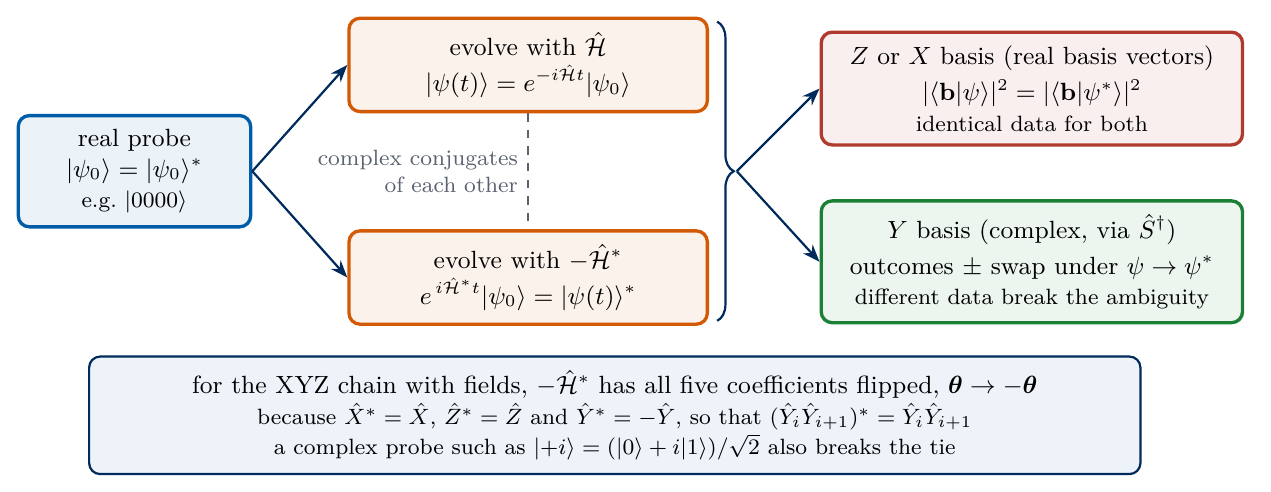

*Complex conjugation maps the evolution under $\hat{\mathcal H}$ to the evolution under $-\hat{\mathcal H}^*$. Real bases see identical data, and the $Y$ basis or a complex probe separates the two Hamiltonians.*

The code evaluates the loss of the estimate $\tilde{\boldsymbol\theta}$ and of its partner $-\tilde{\boldsymbol\theta}$ separately on the $Z$, $X$ and $Y$ parts of the record, and compares the probabilities for a complex probe.

basis Z: L(theta~) = 2.210368, L(-theta~) = 2.210368, difference +0.00e+00
basis X: L(theta~) = 1.880046, L(-theta~) = 1.880046, difference +0.00e+00
basis Y: L(theta~) = 2.467012, L(-theta~) = 3.094208, difference +6.27e-01
complex probe |+i+i+i+i>, Z basis: largest probability difference 0.398
relative distance (7) of the unsuccessful starts of Section 5 from the partner -theta~: [0.54 1.59 1.08 1.52 2.12 1.02 0.49 0.15 0.85]
s = 0 (no evolution): 8120 of 54000 recorded shots show strings of model probability zero


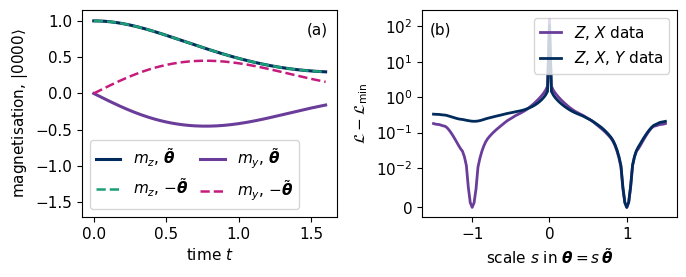

In [7]:
def nll_by_basis(theta, c):
    # loss (5) restricted to each basis g = Z, X, Y
    p = born(theta)
    return np.asarray(-jnp.sum(c * jnp.log(p + 1e-300), axis=(0, 2, 3)) / jnp.sum(c, axis=(0, 2, 3)))

L_plus, L_minus = nll_by_basis(theta_tilde, counts), nll_by_basis(-theta_tilde, counts)
p_plus, p_minus = np.asarray(born(theta_tilde)), np.asarray(born(-theta_tilde))
assert np.max(np.abs(p_plus[:, :2] - p_minus[:, :2])) < 1e-12            # equation (9) for the Z and X bases
assert np.max(np.abs(p_plus[:, 2] - p_minus[:, 2])) > 0.1                  # the Y basis differs
for g_, name in enumerate(BASIS_NAMES):
    print(f"basis {name}: L(theta~) = {L_plus[g_]:.6f}, L(-theta~) = {L_minus[g_]:.6f}, difference {L_minus[g_] - L_plus[g_]:+.2e}")
# a complex probe |+i>^4 separates the pair already in the Z basis
kpi = np.array([1, 1j]) / np.sqrt(2)
born_complex = make_born(P_STACK, jnp.asarray(product_state([kpi] * 4))[None], U_BASES, DT, K_TIMES)
diff_complex = float(jnp.max(jnp.abs(born_complex(theta_tilde)[0, 0] - born_complex(-theta_tilde)[0, 0])))
assert diff_complex > 0.05
print(f"complex probe |+i+i+i+i>, Z basis: largest probability difference {diff_complex:.3f}")
err_partner = rel_error(theta_fits, -theta_tilde)          # equation (7) with the partner -theta~ as the reference
print("relative distance (7) of the unsuccessful starts of Section 5 from the partner -theta~:", np.round(err_partner[errors_starts >= 0.1], 2))
p_zero = np.asarray(born(0 * theta_tilde)); c_np = np.asarray(counts)
print(f"s = 0 (no evolution): {int(c_np[p_zero < 1e-200].sum())} of {int(c_np.sum())} recorded shots show strings of model probability zero")
NUMBERS.update(AmbigZX=("0" if np.max(np.abs(L_plus[:2] - L_minus[:2])) == 0 else sci(float(np.max(np.abs(L_plus[:2] - L_minus[:2]))), 0)), AmbigY=f"{L_minus[2] - L_plus[2]:.2f}")

s_line = np.linspace(-1.5, 1.5, 121)
L_line = np.array([nll_by_basis(s * theta_tilde, counts) for s in s_line])         # [s, basis]
L_zx = L_line[:, :2].mean(axis=1); L_all = L_line.mean(axis=1)                     # equal shots per basis, so means = loss (5)
m_plus = exact_magnetisations(np.asarray(hamiltonian(theta_tilde)), np.asarray(PROBES[0]), t_fine)
m_minus = exact_magnetisations(np.asarray(hamiltonian(-theta_tilde)), np.asarray(PROBES[0]), t_fine)
assert np.allclose(m_plus[:, :2], m_minus[:, :2], atol=1e-10) and np.allclose(m_plus[:, 2], -m_minus[:, 2], atol=1e-10)
def draw_amb_a(ax):
    ax.plot(t_fine, m_plus[:, 0], "-", color=COL["navy"], lw=2.2, label=r"$m_z$, $\tilde{\boldsymbol{\theta}}$")
    ax.plot(t_fine, m_minus[:, 0], "--", color=COL["teal"], lw=1.8, label=r"$m_z$, $-\tilde{\boldsymbol{\theta}}$")
    ax.plot(t_fine, m_plus[:, 2], "-", color=COL["purple"], lw=2.2, label=r"$m_y$, $\tilde{\boldsymbol{\theta}}$")
    ax.plot(t_fine, m_minus[:, 2], "--", color=COL["magenta"], lw=1.8, label=r"$m_y$, $-\tilde{\boldsymbol{\theta}}$")
    ax.set_xlabel(r"time $t$"); ax.set_ylabel(r"magnetisation, $|0000\rangle$")
    ax.set_ylim(-1.7, 1.15); ax.legend(loc="lower left", ncol=2, columnspacing=0.8, handlelength=1.6)

def draw_amb_b(ax):
    ax.plot(s_line, L_zx - L_zx.min(), color=COL["purple"], lw=2, label="$Z$, $X$ data")
    ax.plot(s_line, L_all - L_all.min(), color=COL["navy"], lw=2, label="$Z$, $X$, $Y$ data")
    ax.set_yscale("symlog", linthresh=1e-2); ax.set_xlabel(r"scale $s$ in $\boldsymbol{\theta}=s\,\tilde{\boldsymbol{\theta}}$")
    ax.set_ylabel(r"$\mathcal{L}-\mathcal{L}_{\min}$"); ax.legend(loc="upper right", handlelength=1.4)
figure_set("fig_lab077_ambiguity", [draw_amb_a, draw_amb_b], [(0.88, 0.88), (0.03, 0.88)])

The losses of $\tilde{\boldsymbol\theta}$ and $-\tilde{\boldsymbol\theta}$ on the $Z$ and $X$ data agree to numerical precision, whereas the $Y$ data favour $\tilde{\boldsymbol\theta}$ by a clear margin. Panel (a) shows for the probe $|0000\rangle$ that the $z$ magnetisation is the same for both Hamiltonians and the $y$ magnetisation changes sign. Panel (b) scans the loss along the straight line $\boldsymbol\theta=s\tilde{\boldsymbol\theta}$. With $Z$ and $X$ data alone the loss has two equal minima, at $s=1$ and $s=-1$, and with the $Y$ data added the minimum at $s=-1$ is lifted above the one at $s=1$. It remains a local minimum, in which a gradient method can still stop. One of the nine unsuccessful starts of Section 5 ends close to this partner, at a relative distance (7) of $0.15$ from $-\tilde{\boldsymbol\theta}$, and the others stop in other local minima. The narrow peak of both curves at $s=0$ arises because, without evolution, the probes $|0000\rangle$ and $|0101\rangle$ return a single string with certainty in the $Z$ basis, whereas the record contains other strings, for which the code evaluates the logarithm at the floor $10^{-300}$ that it adds to every model probability. An experiment with only real probes and real bases would report two equally likely Hamiltonians, one with all coefficients of the wrong sign. The same reasoning applies to every model whose Pauli terms are real matrices.

## 7. The error and the number of shots

The estimate $\tilde{\boldsymbol\theta}$ is computed from random bit strings and is therefore a random variable. To measure its spread, we generate ten independent records for each number of shots $M\in\{30,100,300,1000,3000,10000\}$ per configuration and fit each record. All fits start from the estimate $\tilde{\boldsymbol\theta}$ of Section 5, which was obtained from an independent record and lies in the basin of the global minimum, and run 300 Adam steps with step size $0.02$. For independent shots the standard error is expected to fall as $M^{-1/2}$, the shot-noise scaling of independent repetitions. The figure shows the mean relative error (7) against $M$ with a fitted power law.

6 values of M x 10 records x 300 steps in 12.0 s
M =     30: mean relative error 0.0266
M =    100: mean relative error 0.0166
M =    300: mean relative error 0.0074
M =   1000: mean relative error 0.0038
M =   3000: mean relative error 0.0027
M =  10000: mean relative error 0.0016
fitted slope of log(error) against log(M): -0.495


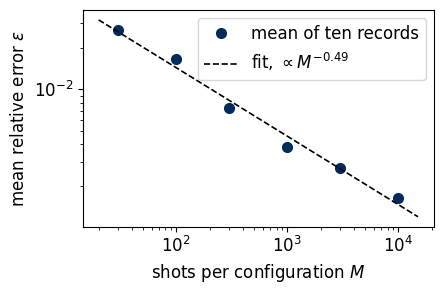

In [8]:
M_LIST = [30, 100, 300, 1000, 3000, 10000]
R_REP, REFIT_STEPS = 10, 300
refit = jax.jit(jax.vmap(lambda c: adam(lambda th: make_nll(born)(th, c), theta_tilde, 0.02, REFIT_STEPS)[0]))
t0 = time.perf_counter()
c_all = []
for M in M_LIST:
    key, k = jax.random.split(key)
    c_all.append(jax.vmap(lambda kk: sample_counts(kk, p_true, M))(jax.random.split(k, R_REP)))
est_all = np.asarray(refit(jnp.concatenate(c_all)))           # all 60 records fitted in one vectorised call
EST = {M: est_all[i * R_REP:(i + 1) * R_REP] for i, M in enumerate(M_LIST)}
t_scan = time.perf_counter() - t0
mean_err = np.array([rel_error(EST[M], theta_true).mean() for M in M_LIST])
slope, intercept = np.polyfit(np.log(M_LIST), np.log(mean_err), 1)
assert -0.65 < slope < -0.35
assert max(rel_error(EST[M], theta_true).max() for M in M_LIST[2:]) < 0.1     # every refit from M >= 300 stays in the right basin
print(f"{len(M_LIST)} values of M x {R_REP} records x {REFIT_STEPS} steps in {t_scan:.1f} s")
for M, e in zip(M_LIST, mean_err):
    print(f"M = {M:6d}: mean relative error {e:.4f}")
print(f"fitted slope of log(error) against log(M): {slope:.3f}")
NUMBERS.update(ShotSlope=f"{slope:.2f}", ErrThousand=f"{mean_err[M_LIST.index(1000)]:.3f}", ErrTenThousand=f"{mean_err[-1]:.4f}")

def draw_shots(ax):
    m_line = np.array([20, 15000])
    ax.loglog(M_LIST, mean_err, "o", color=COL["navy"], ms=7, label="mean of ten records")
    ax.loglog(m_line, np.exp(intercept) * m_line ** slope, "--", color=COL["exact"], lw=1.2, label=fr"fit, $\propto M^{{{slope:.2f}}}$")
    ax.set_xlabel(r"shots per configuration $M$"); ax.set_ylabel(r"mean relative error $\epsilon$"); ax.legend(loc="upper right")
figure_single("fig_lab077_shot_scaling", draw_shots)

The mean relative error falls by a factor of about 17 between $M=30$ and $M=10\,000$, and the fitted exponent $-0.49$ is close to the expected $-1/2$.

## 8. Fisher information and the Cramér–Rao bound

An estimator is unbiased when its mean over many records equals the true value, and no unbiased estimator can be more precise than a limit set by the probabilities themselves. The Fisher information measures how strongly the probabilities of the outcomes change when a coefficient changes. For one shot in every configuration it is the matrix
$$\mathcal I_{jl}(\boldsymbol\theta)=\sum_c\sum_{\mathbf b}\frac{1}{p_{\boldsymbol\theta}(\mathbf b\,|\,c)}\,\frac{\partial p_{\boldsymbol\theta}(\mathbf b\,|\,c)}{\partial\theta_j}\,\frac{\partial p_{\boldsymbol\theta}(\mathbf b\,|\,c)}{\partial\theta_l} . \tag{10}$$
As an example, a single qubit with the Hamiltonian $\theta\hat X$ that starts in $|0\rangle$ returns the bit 0 with the probability $\cos^2(\theta t)$ after the time $t$, and equation (10) gives $\mathcal I=4t^2$, so a longer evolution is more informative about $\theta$. A coefficient to which no probability responds gives a zero row of $\mathcal I$ and cannot be learned. With $M$ independent shots per configuration the information is $M\mathcal I$. The Cramér–Rao bound [5,6] states that the covariance of any unbiased estimator obeys $\mathrm{Cov}(\tilde{\boldsymbol\theta})\succeq\mathcal I^{-1}/M$, which means that the difference of the two matrices is positive semidefinite, so in particular
$$\sigma_{\tilde\theta_j}\geq\sqrt{(\mathcal I^{-1})_{jj}/M}\propto M^{-1/2} . \tag{11}$$
The maximum-likelihood estimate reaches this bound when the number of shots is large, so equation (11) predicts the error bars of Section 7. Ref. [7] develops the Fisher information for quantum measurements. The derivatives in equation (10) come from `jax.jacfwd`. We evaluate $\mathcal I$ at the true coefficients, whereas an experimenter would use $\tilde{\boldsymbol\theta}$, with nearly the same bound. The figure compares the standard deviation of each coefficient over the ten records of Section 7 with $\sqrt{(\mathcal I^{-1})_{jj}/M}$.

sqrt((I^-1)_jj) for M = 1 at the true coefficients: {'Jx': 0.082, 'Jy': 0.083, 'Jz': 0.109, 'hx': 0.069, 'hz': 0.1}
                         at the estimate          : {'Jx': 0.082, 'Jy': 0.083, 'Jz': 0.109, 'hx': 0.069, 'hz': 0.1}
measured / bound for M = 30 ... 10000 (rows), coefficients (columns):
[[1.   1.47 1.35 0.83 0.84]
 [0.7  0.9  1.19 1.25 1.26]
 [0.68 0.64 1.08 1.25 1.04]
 [0.84 0.78 0.97 1.   0.8 ]
 [0.83 1.61 0.86 0.95 1.12]
 [0.99 1.36 1.14 1.48 1.02]]
mean ratio for M >= 300: 1.02


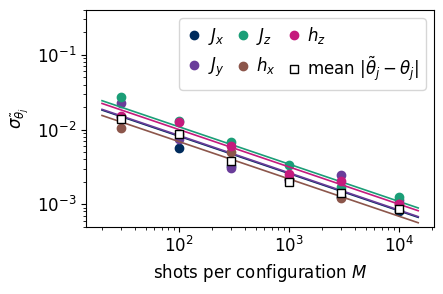

In [9]:
def fisher_per_shot(born_fn, theta):
    # equation (10): Fisher information per shot of every configuration
    p = born_fn(theta)
    dp = jax.jacfwd(born_fn)(theta)                 # [..., parameter]
    w = jnp.where(p > 1e-14, 1.0 / jnp.maximum(p, 1e-14), 0.0)
    return np.asarray(jnp.einsum("...j,...,...l->jl", dp, w, dp))

fisher1 = fisher_per_shot(born, theta_true)
fisher1_est = fisher_per_shot(born, theta_tilde)
assert np.all(np.linalg.eigvalsh(fisher1) > 0)                                    # all five coefficients are identifiable
crb1 = np.sqrt(np.diag(np.linalg.inv(fisher1)))                                   # bound for M = 1, equation (11)
crb1_est = np.sqrt(np.diag(np.linalg.inv(fisher1_est)))
std_meas = np.array([EST[M].std(axis=0, ddof=1) for M in M_LIST])           # [M, coefficient]
ratio = std_meas / (crb1[None, :] / np.sqrt(np.array(M_LIST))[:, None])
ratio_large = ratio[2:].mean()
assert 0.6 < ratio_large < 1.5            # ten records determine a standard deviation to about 25 %
print("sqrt((I^-1)_jj) for M = 1 at the true coefficients:", {k_: float(v) for k_, v in zip(NAMES, np.round(crb1, 3))})
print("                         at the estimate          :", {k_: float(v) for k_, v in zip(NAMES, np.round(crb1_est, 3))})
print("measured / bound for M = 30 ... 10000 (rows), coefficients (columns):")
print(np.round(ratio, 2))
print(f"mean ratio for M >= 300: {ratio_large:.2f}")
NUMBERS.update(CRBRatio=f"{ratio_large:.2f}", CRBJxThousand=sci(crb1[0] / np.sqrt(1000)), CRBJzThousand=sci(crb1[2] / np.sqrt(1000)))
assert NAMES[int(np.argmax(crb1))] == "Jz"                               # J_z has the largest bound (text of this section)

M_axis = np.logspace(np.log10(20), np.log10(15000), 50)
def draw_crb(ax):
    for j, name in enumerate(NAMES):
        ax.loglog(M_LIST, std_meas[:, j], "o", color=COEF_COL[j], ms=6, label=COEF_LABEL[name])
        ax.loglog(M_axis, crb1[j] / np.sqrt(M_axis), "-", color=COEF_COL[j], lw=1.2)
    ax.loglog(M_LIST, mean_err * np.abs(np.asarray(theta_true)).sum() / 5, "s", color=COL["exact"], mfc="white", ms=6,
              label=r"mean $|\tilde\theta_j-\theta_j|$")
    ax.set_xlabel(r"shots per configuration $M$"); ax.set_ylabel(r"$\sigma_{\tilde\theta_j}$")
    ax.set_ylim(5e-4, 0.4); ax.legend(loc="upper right", ncol=3, columnspacing=0.6, handlelength=1.0, handletextpad=0.3)
figure_single("fig_lab077_cramer_rao", draw_crb)

The markers are the measured standard deviations of the five coefficients and the lines of the same colour are the Cramér–Rao bounds (11). A standard deviation estimated from ten records is itself uncertain by about 25 %, so the individual ratios in the printed table scatter between $0.6$ and $1.6$, and values below one are sampling noise. The open squares repeat the mean relative error of Section 7, converted to the mean absolute deviation of one coefficient, $\epsilon\sum_j|\theta_j|/5$, and they follow the same $M^{-1/2}$ law. From $M=300$ on, the ratio of the measured spread to the bound is consistent with one, with a mean of 1.02, and the fitted slope of the mean error in Section 7 is close to $-1/2$. The coupling $J_z$ has the largest bound, which means that the probabilities respond least to a change of its value. A tenfold reduction of every error bar costs a hundredfold increase in the number of shots, and the Fisher information indicates which probes, times and bases would reduce a chosen error bar most efficiently.

## 9. Learning decay and dephasing rates

A real qubit also exchanges energy and phase with its environment, and its density matrix $\hat\rho$ obeys the Lindblad equation [8,9],
$$\frac{d\hat\rho}{dt}=-i[\hat{\mathcal H},\hat\rho]+\sum_\mu\Big(\hat L_\mu\hat\rho\hat L_\mu^\dagger-\frac12\big\{\hat L_\mu^\dagger\hat L_\mu,\hat\rho\big\}\Big) , \tag{12}$$
where the jump operators $\hat L_\mu$ describe the processes caused by the environment and $\{\hat A,\hat B\}=\hat A\hat B+\hat B\hat A$. We take one qubit with two such processes. Energy decay has the jump operator $\hat L_1=\sqrt\Gamma\,\hat S^+$ with $\hat S^+=|0\rangle\langle1|$, which takes the qubit from $|1\rangle$ to the ground state $|0\rangle=|g\rangle$ of the bare qubit. The operator carries a plus because $|0\rangle$ is the spin-up state in our convention. Pure dephasing has $\hat L_2=\sqrt{\gamma/2}\,\hat Z$, which randomises the relative phase of $|0\rangle$ and $|1\rangle$ without changing the populations. Without a Hamiltonian, equation (12) with these two operators gives
$$\frac{d\rho_{11}}{dt}=-\Gamma\rho_{11},\qquad\frac{d\rho_{01}}{dt}=-\Big(\frac\Gamma2+\gamma\Big)\rho_{01} , \tag{13}$$
so the population of $|1\rangle$ relaxes with the time $T_1=1/\Gamma$ and the coherence decays with $1/T_2=\Gamma/2+\gamma$. The qubit is also driven by the known Hamiltonian $\hat{\mathcal H}=(\Omega/2)\hat X$ with the Rabi frequency $\Omega=1$, the angular frequency at which a resonant drive rotates the qubit between $|0\rangle$ and $|1\rangle$. The drive rotates populations into coherences, so that both rates affect both kinds of data. The unknowns are $\Gamma$ and $\gamma$, with true values $\Gamma=0.3$ and $\gamma=0.2$. The goal is to estimate both rates from bit strings alone, and we count the fit as successful when the estimates agree with the true rates within their statistical errors and these errors reach the Cramér–Rao bound (11).

Equation (12) is linear in $\hat\rho$. Writing the $2\times2$ matrix as the vector $\mathrm{vec}(\hat\rho)$ of its rows, and using $\mathrm{vec}(\hat A\hat\rho\hat B)=(\hat A\otimes\hat B^{T})\,\mathrm{vec}(\hat\rho)$, turns it into $d\,\mathrm{vec}(\hat\rho)/dt=\mathbb L\,\mathrm{vec}(\hat\rho)$ with the $4\times4$ Liouvillian
$$\mathbb L=-i\big(\hat{\mathcal H}\otimes\hat I-\hat I\otimes\hat{\mathcal H}^{T}\big)+\sum_\mu\Big(\hat L_\mu\otimes\hat L_\mu^{*}-\frac12\hat L_\mu^\dagger\hat L_\mu\otimes\hat I-\frac12\hat I\otimes(\hat L_\mu^\dagger\hat L_\mu)^{T}\Big) . \tag{14}$$
The state at time $t$ is $e^{\mathbb Lt}\,\mathrm{vec}(\hat\rho_0)$, computed with equation (3), and the code checks it against a direct fourth-order Runge–Kutta integration [10] of equation (12). The probes are $|1\rangle$ and $|+\rangle$, the bases are $Z$ and $X$, the times are $t_n=0.5n$ with $n=1,\dots,8$, and the probability of outcome $b$ is $\langle b|\hat U_g\hat\rho(t_n)\hat U_g^\dagger|b\rangle$. The model keeps the rates positive by writing them through the softplus function,
$$\Gamma=\ln\big(1+e^{a_\Gamma}\big),\qquad\gamma=\ln\big(1+e^{a_\gamma}\big) , \tag{15}$$
and Adam updates the unconstrained numbers $a_\Gamma$ and $a_\gamma$. The loss is again equation (5), and the sketch shows the experiment and the fit.

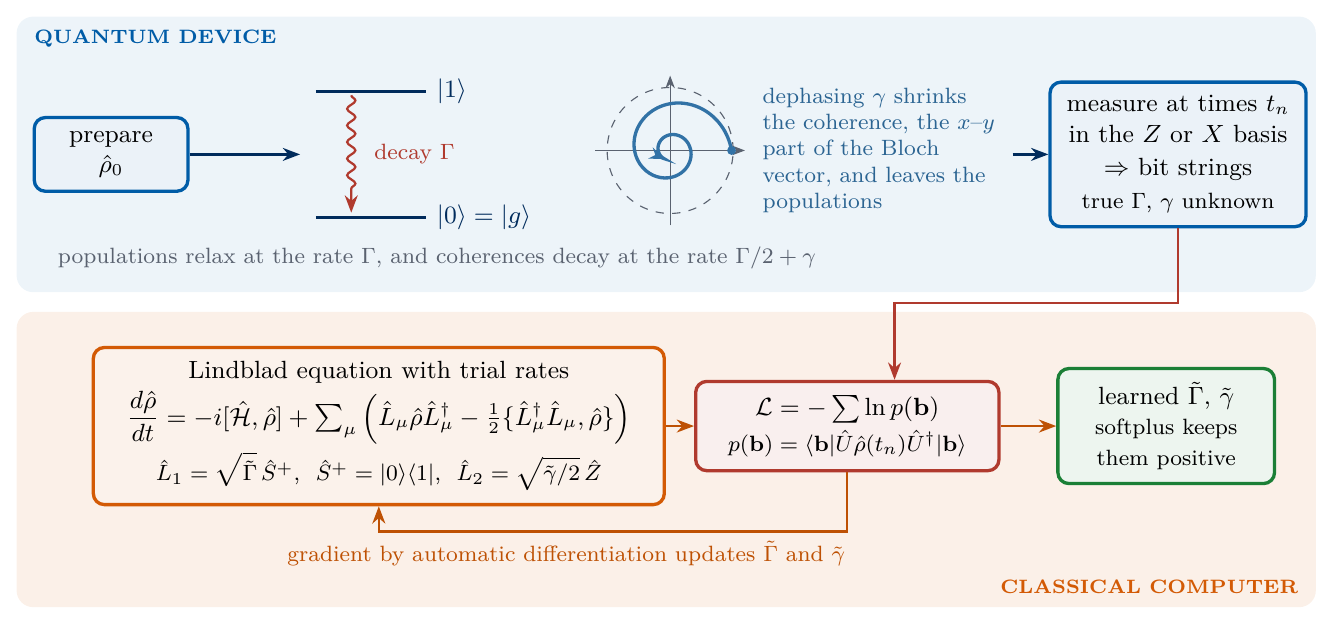

*Learning two rates of an open qubit. Probes evolve under the Lindblad equation with unknown $\Gamma$ and $\gamma$, bit strings in the $Z$ and $X$ bases feed the same negative log-likelihood, and automatic differentiation through the evolution updates the rates.*

The first cell defines the Liouvillian, the probabilities and the loss, and checks equation (14) against the Runge–Kutta integration and against the rates of equation (13).

In [10]:
OMEGA, GAMMA_TRUE, DEPH_TRUE = 1.0, 0.3, 0.2
S_PLUS = np.array([[0, 1], [0, 0]], dtype=complex)          # |0><1|: decay to the ground state |0>
H_Q = jnp.asarray(OMEGA / 2 * X)
I2j = jnp.eye(2, dtype=complex)

def liouvillian(rates):
    # equation (14) for L_1 = sqrt(Gamma) S+, L_2 = sqrt(gamma/2) Z; vec() stacks the rows of rho
    Gamma, gamma = rates[0], rates[1]
    L_ops = [jnp.sqrt(Gamma) * jnp.asarray(S_PLUS), jnp.sqrt(gamma / 2) * jnp.asarray(Z)]
    Lv = -1j * (jnp.kron(H_Q, I2j) - jnp.kron(I2j, H_Q.T))
    for Lk in L_ops:
        LdL = Lk.conj().T @ Lk
        Lv = Lv + jnp.kron(Lk, Lk.conj()) - 0.5 * jnp.kron(LdL, I2j) - 0.5 * jnp.kron(I2j, LdL.T)
    return Lv

def lindblad_rhs(rho, rates):
    # right-hand side of equation (12) in matrix form, used only for the check
    Gamma, gamma = rates
    out = -1j * (np.asarray(H_Q) @ rho - rho @ np.asarray(H_Q))
    for Lk in (np.sqrt(Gamma) * S_PLUS, np.sqrt(gamma / 2) * Z):
        LdL = Lk.conj().T @ Lk
        out = out + Lk @ rho @ Lk.conj().T - 0.5 * (LdL @ rho + rho @ LdL)
    return out

RHO0 = jnp.asarray(np.array([np.outer(k1, k1.conj()), np.outer(kp, kp.conj())]).reshape(2, 4))   # probes |1>, |+>
U_BASES_1 = jnp.asarray(np.array([I2, HAD]))
DT_L, K_L = 0.5, 8
TIMES_L = DT_L * np.arange(1, K_L + 1)

def softplus(a): return jnp.logaddexp(0.0, a)
def inv_softplus(x): return float(np.log(np.expm1(x)))

def born_lindblad(rates):
    # probabilities p[probe, basis, time, b] for given rates (Gamma, gamma)
    E = expm_taylor(liouvillian(rates) * DT_L)
    def step(r, _):
        r = r @ E.T
        return r, r
    _, traj = jax.lax.scan(step, RHO0, None, length=K_L)          # [time, probe, 4]
    rho = traj.reshape(K_L, 2, 2, 2)
    probs = jnp.real(jnp.einsum("gba,kpac,gbc->pgkb", U_BASES_1, rho, U_BASES_1.conj()))
    return jnp.clip(probs, 1e-15, 1.0)

rates_true = jnp.array([GAMMA_TRUE, DEPH_TRUE])
# check equation (14) against a Runge-Kutta integration of equation (12) for the probe |+>;
# one fourth-order step of size h: rho(t + h) = rho + h/6 (k1 + 2 k2 + 2 k3 + k4), with k1 ... k4 the right-hand side at four trial states
rho = np.outer(kp, kp.conj()); h_rk = 0.005
for _ in range(int(round(TIMES_L[3] / h_rk))):
    k1_ = lindblad_rhs(rho, (GAMMA_TRUE, DEPH_TRUE)); k2_ = lindblad_rhs(rho + h_rk / 2 * k1_, (GAMMA_TRUE, DEPH_TRUE))
    k3_ = lindblad_rhs(rho + h_rk / 2 * k2_, (GAMMA_TRUE, DEPH_TRUE)); k4_ = lindblad_rhs(rho + h_rk * k3_, (GAMMA_TRUE, DEPH_TRUE))
    rho = rho + h_rk / 6 * (k1_ + 2 * k2_ + 2 * k3_ + k4_)
E4 = scipy.linalg.expm(np.asarray(liouvillian(rates_true)) * TIMES_L[3])
rho_vec = (E4 @ np.outer(kp, kp.conj()).reshape(4)).reshape(2, 2)
assert np.allclose(rho_vec, rho, atol=1e-10)
assert abs(np.trace(rho_vec) - 1) < 1e-12 and np.linalg.eigvalsh(rho_vec).min() > -1e-12
# equation (13): without drive the population and the coherence decay at Gamma and Gamma/2 + gamma
H_save = H_Q; H_Q = jnp.zeros((2, 2), complex)
Lv0 = np.asarray(liouvillian(rates_true)); H_Q = H_save
assert np.isclose(Lv0[3, 3].real, -GAMMA_TRUE) and np.isclose(Lv0[1, 1].real, -(GAMMA_TRUE / 2 + DEPH_TRUE))
p_L = born_lindblad(rates_true)
assert np.allclose(p_L.sum(-1), 1, atol=1e-12)
print("Liouvillian (14) agrees with the Runge-Kutta integration of equation (12) and with the rates of equation (13)")


Liouvillian (14) agrees with the Runge-Kutta integration of equation (12) and with the rates of equation (13)


We first fit one record with $M=1000$ shots for each of the $2\times2\times8=32$ configurations of probe, basis and time. The fit starts from $\Gamma=\gamma=1$, far from the true rates, and runs 400 Adam steps with step size $0.05$.

In [11]:
nll_L = lambda a, c: -jnp.sum(c * jnp.log(born_lindblad(softplus(a)))) / jnp.sum(c)
a_start = jnp.array([inv_softplus(1.0), inv_softplus(1.0)])          # initial guess Gamma = gamma = 1
fit_L = jax.jit(jax.vmap(lambda c: adam(lambda a: nll_L(a, c), a_start, 0.05, 400)[0]))
key, k = jax.random.split(key)
counts_L = sample_counts(k, p_L, M_MAIN)
rates_fit = np.asarray(softplus(fit_L(counts_L[None])[0]))
assert np.all(np.abs(rates_fit - np.asarray(rates_true)) < 0.05)
print(f"one record with M = {M_MAIN}: Gamma~ = {rates_fit[0]:.4f} (true {GAMMA_TRUE}), gamma~ = {rates_fit[1]:.4f} (true {DEPH_TRUE})")
print(f"T1 = 1/Gamma~ = {1 / rates_fit[0]:.2f}, T2 = 1/(Gamma~/2 + gamma~) = {1 / (rates_fit[0] / 2 + rates_fit[1]):.2f}")


one record with M = 1000: Gamma~ = 0.2968 (true 0.3), gamma~ = 0.1994 (true 0.2)
T1 = 1/Gamma~ = 3.37, T2 = 1/(Gamma~/2 + gamma~) = 2.88


To measure the statistical error we repeat the fit for 20 independent records at each of the six numbers of shots $M$ of Section 7, with the same starting values and the same 400 steps, and compare the standard deviation of the 20 estimates with the Cramér–Rao bound (11). In the figure, panel (a) shows the record and the fitted model of the single fit and panel (b) the standard deviations against $M$.

standard deviations of (Gamma~, gamma~) over 20 records: {30: [0.0763, 0.0735], 100: [0.0468, 0.0359], 300: [0.0251, 0.0242], 1000: [0.0147, 0.0122], 3000: [0.0066, 0.006], 10000: [0.0042, 0.0036]}
measured / Cramer-Rao bound, mean over M >= 300: 1.03
single fit of the first cell: deviation from the true rates 0.22 (Gamma) and 0.05 (gamma) standard deviations at M = 1000
runtime of Sections 1 to 9: 54.3 s (shot scan 12.0 s, starts 4.4 s)


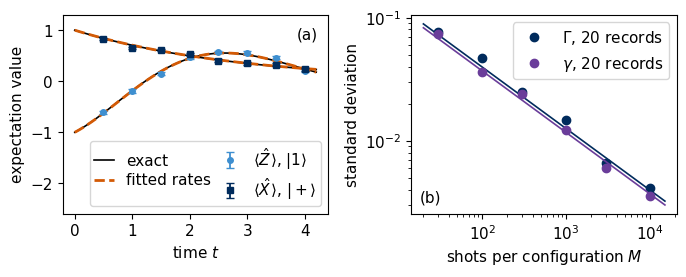

In [12]:
# error against the number of shots and the Cramer-Rao bound of equation (11)
fisher1_L = fisher_per_shot(born_lindblad, rates_true)
crb_L = np.sqrt(np.diag(np.linalg.inv(fisher1_L)))
R_L = 20
cL_all = []
for M in M_LIST:
    key, k = jax.random.split(key)
    cL_all.append(jax.vmap(lambda kk: sample_counts(kk, p_L, M))(jax.random.split(k, R_L)))
rates_all = np.asarray(softplus(fit_L(jnp.concatenate(cL_all))))
std_L = np.array([rates_all[i * R_L:(i + 1) * R_L].std(axis=0, ddof=1) for i in range(len(M_LIST))])
ratio_L = (std_L / (crb_L[None, :] / np.sqrt(np.array(M_LIST))[:, None]))[2:].mean()
assert 0.7 < ratio_L < 1.4
print("standard deviations of (Gamma~, gamma~) over 20 records:", {M: np.round(s, 4).tolist() for M, s in zip(M_LIST, std_L)})
print(f"measured / Cramer-Rao bound, mean over M >= 300: {ratio_L:.2f}")
dev_L = (rates_fit - np.asarray(rates_true)) / std_L[M_LIST.index(M_MAIN)]
print(f"single fit of the first cell: deviation from the true rates {abs(dev_L[0]):.2f} (Gamma) and {abs(dev_L[1]):.2f} (gamma) standard deviations at M = {M_MAIN}")
NUMBERS.update(LindGamma=f"{rates_fit[0]:.3f}", LindDeph=f"{rates_fit[1]:.3f}", LindCRBRatio=f"{ratio_L:.2f}")

t_fineL = np.linspace(0, 4.2, 120)
def lindblad_curves(rates):
    Lv = np.asarray(liouvillian(jnp.asarray(rates)))
    out = []
    for t in t_fineL:
        E = scipy.linalg.expm(Lv * t)
        r1 = (E @ np.asarray(RHO0[0])).reshape(2, 2); rp = (E @ np.asarray(RHO0[1])).reshape(2, 2)
        out.append([np.real(np.trace(Z @ r1)), np.real(np.trace(X @ rp))])
    return np.array(out)
cur_true, cur_fit = lindblad_curves(np.asarray(rates_true)), lindblad_curves(rates_fit)
zdat = (counts_L[0, 0, :, 0] - counts_L[0, 0, :, 1]) / M_MAIN       # <Z> of the probe |1> from z-basis counts
xdat = (counts_L[1, 1, :, 0] - counts_L[1, 1, :, 1]) / M_MAIN       # <X> of the probe |+> from x-basis counts
def draw_lind_a(ax):
    ax.plot(t_fineL, cur_true[:, 0], "-", color=COL["exact"], lw=1.2, label="exact")
    ax.plot(t_fineL, cur_fit[:, 0], "--", color=COL["model"], lw=2, label="fitted rates")
    ax.errorbar(TIMES_L, np.asarray(zdat), yerr=np.sqrt(1 - np.asarray(zdat) ** 2) / np.sqrt(M_MAIN), fmt="o", color=COL["data"], ms=4, capsize=3, elinewidth=1.3, label=r"$\langle\hat Z\rangle$, $|1\rangle$")
    ax.plot(t_fineL, cur_true[:, 1], "-", color=COL["exact"], lw=1.2)
    ax.plot(t_fineL, cur_fit[:, 1], "--", color=COL["model"], lw=2)
    ax.errorbar(TIMES_L, np.asarray(xdat), yerr=np.sqrt(1 - np.asarray(xdat) ** 2) / np.sqrt(M_MAIN), fmt="s", color=COL["navy"], ms=4, capsize=3, elinewidth=1.3, label=r"$\langle\hat X\rangle$, $|+\rangle$")
    ax.set_xlabel(r"time $t$"); ax.set_ylabel("expectation value"); ax.set_ylim(-2.6, 1.3)
    ax.legend(loc="lower right", ncol=2, handlelength=1.3, columnspacing=0.6, borderpad=0.3, labelspacing=0.3)

def draw_lind_b(ax):
    for j, (lab, col) in enumerate(zip([r"$\Gamma$", r"$\gamma$"], [COL["navy"], COL["purple"]])):
        ax.loglog(M_LIST, std_L[:, j], "o", color=col, ms=6, label=lab + ", 20 records")
        ax.loglog(M_axis, crb_L[j] / np.sqrt(M_axis), "-", color=col, lw=1.2)
    ax.set_xlabel(r"shots per configuration $M$"); ax.set_ylabel("standard deviation"); ax.legend(loc="upper right")
figure_set("fig_lab077_lindblad", [draw_lind_a, draw_lind_b], [(0.88, 0.88), (0.03, 0.06)])
CORE_SECONDS = time.perf_counter() - started
print(f"runtime of Sections 1 to 9: {CORE_SECONDS:.1f} s (shot scan {t_scan:.1f} s, starts {t_fit:.1f} s)")

In panel (a) the probe $|1\rangle$ relaxes towards the ground state while the drive rotates it, so $\langle\hat Z\rangle$ oscillates and approaches a steady value, and the coherence of the probe $|+\rangle$ decays. The model with the fitted rates, dashed, follows the exact curves and the data within their error bars. Panel (b) shows that the standard deviations of $\tilde\Gamma$ and $\tilde\gamma$ fall as $M^{-1/2}$ along their Cramér–Rao bounds, as for the Hamiltonian coefficients. The single fit deviates from the true rates by $0.22$ and $0.05$ standard deviations, and for $M\geq300$ the measured spread is $1.03$ times the bound, so both success criteria of this section are met. Only the forward model changed, which now propagates a density matrix with the Liouvillian (14) in place of a state vector with the Hamiltonian. The core route ends here. The last code cell of the notebook prints the numbers and the runtime and runs directly from this point, and the exercises follow in Section 12.

## 10. Rugged landscapes and the PXP model

This section is for work at home, and its first code cell takes about three minutes. Learning the coefficients of a fixed model from measurements after a controlled evolution was introduced as Bayesian Hamiltonian learning [11,12] and demonstrated experimentally [13]. Ref. [14] fits the likelihood of time-resolved bit strings for one-dimensional chains in a scalable way, and Ref. [1] calls the fit of Sections 4 and 5 the vanilla model. We call it the plain model. Section 5 showed its weak point, since many starts end in local minima and the method succeeds only when a start lies in the basin of the global minimum. We measure how often a single start succeeds, for the XYZ chain and for a second model with a kinetic constraint, the PXP model.

Neutral atoms excited to high-lying Rydberg states realise a strongly constrained Hamiltonian [19]. Each atom is a qubit with the ground state $|0\rangle=|g\rangle$ and the Rydberg state $|1\rangle=|r\rangle$, and a laser with Rabi frequency $\Omega_i$ drives the transition of atom $i$. Two neighbouring atoms in the Rydberg state interact so strongly that the laser cannot excite them both, an effect called the Rydberg blockade. In the limit of perfect blockade the dynamics is described by the PXP model [20–22],
$$\hat{\mathcal H}_{\mathrm{PXP}}(\boldsymbol\Omega)=\sum_{i=0}^{N-1}\Omega_i\,\hat P^{(0)}_{i-1}\hat X_i\hat P^{(0)}_{i+1},\qquad\hat P^{(0)}_i=|0\rangle\langle0|_i , \tag{16}$$
where $\hat X_i$ flips atom $i$ between ground and Rydberg state, and the projectors $\hat P^{(0)}_{i\pm1}$ onto the ground state allow the flip only when both neighbours are in it. At the ends of the chain the missing neighbour is replaced by the identity, $\hat P^{(0)}_{-1}=\hat P^{(0)}_N=\hat I$. The blocked level is therefore the Rydberg state $|1\rangle$, and from a state without neighbouring excitations the evolution never creates a pair $11$ on neighbouring atoms. The unknowns are the $N$ Rabi frequencies $\boldsymbol\Omega=(\Omega_0,\dots,\Omega_{N-1})$. The model contains three-qubit terms and is far from a sum of independent spins, although every coefficient multiplies a known operator as in equation (1).

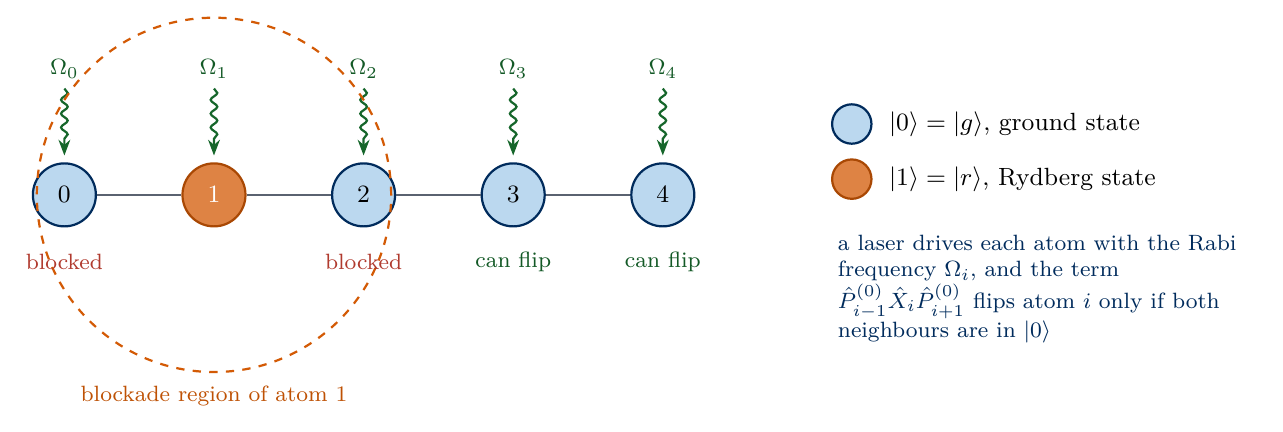

*PXP chain of five atoms. A laser with Rabi frequency $\Omega_i$ drives each atom, and an atom flips only when both neighbours are in the ground state $|0\rangle$, so the excited atom 1 blocks its neighbours 0 and 2.*

The data are generated as in Section 3, with the $Z$, $X$ and $Y$ bases, the five times $t_n=0.2n$ and $M=1000$ shots per configuration. The three probes are random computational basis states without neighbouring Rydberg atoms, which the device prepares by exciting selected atoms. For the XYZ chain used for comparison they are drawn from all basis states. The transformation $\hat{\mathcal H}\to\hat Z_i\hat{\mathcal H}\hat Z_i$ flips the sign of $\Omega_i$ alone, because $\hat Z_i\hat X_i\hat Z_i=-\hat X_i$ and $\hat Z_i$ commutes with the projectors. The probes, computational basis states, change under $\hat Z_i$ only by a sign, and $Z$-basis data stay unchanged. The $Z$ data therefore cannot distinguish the $2^N$ sign patterns of $\boldsymbol\Omega$, and only the $X$ and $Y$ data select one of them. The code checks the blockade and this sign symmetry.

The experiment consists of 16 independent problems for each model and size. Every problem has its own true coefficients, drawn uniformly from $[-1,1]$ as in Ref. [1], its own record of bit strings and one start, drawn uniformly from the same interval. The fit runs 1000 Adam steps with step size $0.05$ for four and five qubits and 600 steps for six atoms, so the six-atom result comes from a shorter fit than the others. A fit counts as successful when its relative error (7) is below $0.1$, and the success rate is the fraction of successful problems. The cell tests the XYZ chain with four qubits and the PXP model with four, five and six atoms. Its first figure shows the success rates as bars, together with the rates of the plain model published in Table 1 of arXiv:2408.08639v1 (Ref. [1]) for the PXP model as black diamonds. The published rates were measured with a different data set, 200 random Pauli bases per time and five probes, in 50 problems. The second figure draws the whole published table, for the PXP model and for a Heisenberg chain in a field, with the plain model as dashed lines and the neural differential equation of Section 11 as solid lines.

N = 6: 21 of 64 basis states have no neighbouring Rydberg pair; the PXP Hamiltonian never leaves them
XYZ, N = 4: probes ['1010', '1110', '0010'], success 3 of 16 (epsilon < 0.1), 12.6 s
    relative errors, sorted: [0.   0.01 0.01 0.76 0.83 1.06 1.19 1.29 1.36 1.4  1.53 1.67 1.82 1.93
 1.96 1.98]
PXP, N = 4: probes ['1000', '0101', '0010'], success 0 of 16 (epsilon < 0.1), 8.1 s
    relative errors, sorted: [0.32 0.44 0.48 0.49 0.5  0.62 0.92 0.95 1.01 1.06 1.12 1.2  1.31 1.58
 1.76 1.9 ]
PXP, N = 5: probes ['00100', '01010', '10101'], success 2 of 16 (epsilon < 0.1), 35.2 s
    relative errors, sorted: [0.01 0.01 0.35 0.36 0.45 0.5  0.62 0.83 0.87 0.88 0.97 0.99 1.23 1.31
 1.99 2.25]
PXP, N = 6: probes ['101001', '010001', '010010'], success 0 of 16 (epsilon < 0.1), 61.8 s
    relative errors, sorted: [0.34 0.66 0.72 0.73 0.77 0.79 0.83 0.87 0.88 0.94 0.97 1.12 1.14 1.58
 1.72 2.24]


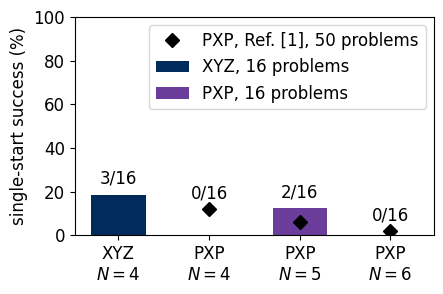

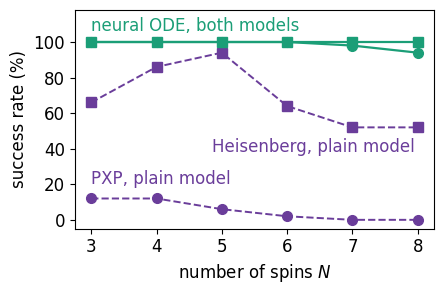

In [13]:
# work at home, about three minutes on a laptop CPU, most of it for PXP with N = 6;
# remove the last entry of the list in the loop below for a shorter run (the closing cell then still works)
P_GROUND = np.diag([1, 0]).astype(complex)                    # projector on the ground state |0> = |g>
N_RYD = np.diag([0, 1]).astype(complex)                       # number operator of the Rydberg state |1> = |r>

def pxp_terms(n):
    # the N matrices of equation (16), keyed by the name of their Rabi frequency
    out = {}
    for i in range(n):
        f = {i: X}
        if i > 0: f[i - 1] = P_GROUND
        if i < n - 1: f[i + 1] = P_GROUND
        out[f"Omega{i}"] = op(n, f)
    return out

def bits(i, n): return [(i >> (n - 1 - q)) & 1 for q in range(n)]
T6 = pxp_terms(6)
H6 = sum(np.random.default_rng(0).uniform(-1, 1) * T6[k] for k in T6)
allowed = np.array([not any(b[q] and b[q + 1] for q in range(5)) for b in (bits(i, 6) for i in range(64))])
assert np.allclose(H6[np.ix_(~allowed, allowed)], 0)          # no transition into states with neighbouring Rydberg atoms
Z0 = op(6, {0: Z})
th6 = np.random.default_rng(0).uniform(-1, 1, 6)
H_a = sum(t * T6[k] for t, k in zip(th6, T6)); th6_flip = th6.copy(); th6_flip[0] *= -1
H_b = sum(t * T6[k] for t, k in zip(th6_flip, T6))
assert np.allclose(Z0 @ H_a @ Z0, H_b)                        # H -> Z_0 H Z_0 flips the sign of Omega_0 only
print(f"N = 6: {allowed.sum()} of 64 basis states have no neighbouring Rydberg pair; the PXP Hamiltonian never leaves them")

DT_P, K_P, M_P = 0.2, 5, 1000
def blockade_states(n):
    # computational basis states without two neighbouring Rydberg atoms
    return [i for i in range(2 ** n) if not any(bits(i, n)[q] and bits(i, n)[q + 1] for q in range(n - 1))]

def make_experiment(terms, n, seed, blockade):
    # three random computational-basis probes (from the blockade subspace if blockade), Z/X/Y bases, times 0.2 ... 1.0
    rng = np.random.default_rng(seed)
    pool = blockade_states(n) if blockade else list(range(2 ** n))
    probe_idx = rng.choice(pool, 3, replace=False)
    probes = jnp.eye(2 ** n, dtype=complex)[jnp.asarray(probe_idx)]
    P = jnp.asarray(np.array(list(terms.values())))
    return P, jax.jit(make_born(P, probes, basis_rotations(n), DT_P, K_P)), [format(int(i), f"0{n}b") for i in probe_idx], probes

def success_runs(terms, n, runs, steps, seed, label_is_pxp):
    # `runs` independent problems: random true coefficients and one random start in [-1, 1], one record of M_P shots each
    P, born_m, probe_bits, _ = make_experiment(terms, n, seed, blockade=label_is_pxp)
    nll_m = make_nll(born_m)
    k_true, k_start, k_data = jax.random.split(jax.random.PRNGKey(seed), 3)
    n_par = len(terms)
    truths = jax.random.uniform(k_true, (runs, n_par), minval=-1, maxval=1)
    starts_ = jax.random.uniform(k_start, (runs, n_par), minval=-1, maxval=1)
    data = jax.vmap(lambda kk, th: sample_counts(kk, born_m(th), M_P))(jax.random.split(k_data, runs), truths)
    fits = jax.jit(jax.vmap(lambda th0, c: adam(lambda th: nll_m(th, c), th0, 0.05, steps)[0]))(starts_, data)
    err = np.abs(np.asarray(fits) - np.asarray(truths)).sum(1) / np.abs(np.asarray(truths)).sum(1)
    return err, probe_bits

RUNS, STEPS_B = 16, {4: 1000, 5: 1000, 6: 600}        # problems per case; Adam steps for N = 4, 5, 6
SUCCESS = {}
for label, terms, n in [("XYZ, N = 4", xyz_terms(4), 4), ("PXP, N = 4", pxp_terms(4), 4),
                        ("PXP, N = 5", pxp_terms(5), 5), ("PXP, N = 6", pxp_terms(6), 6)]:
    t0 = time.perf_counter()
    err, probe_bits = success_runs(terms, n, RUNS, STEPS_B[n], seed=100 + n + (10 if label.startswith("XYZ") else 0),
                                   label_is_pxp=label.startswith("PXP"))
    SUCCESS[label] = dict(rate=float(np.mean(err < 0.1)), errors=err.tolist(), probes=probe_bits, seconds=time.perf_counter() - t0)
    print(f"{label}: probes {probe_bits}, success {int(np.sum(err < 0.1))} of {RUNS} "
          f"(epsilon < 0.1), {SUCCESS[label]['seconds']:.1f} s")
    print("    relative errors, sorted:", np.round(np.sort(err), 2))
succ_count = lambda l_: int(round(RUNS * SUCCESS[l_]["rate"])) if l_ in SUCCESS else None       # None if a case was removed from the loop
NUMBERS.update(SuccXYZ=f"{succ_count('XYZ, N = 4')}", SuccPXPfour=f"{succ_count('PXP, N = 4')}",
               SuccPXPfive=f"{succ_count('PXP, N = 5')}", SuccPXPsix=f"{succ_count('PXP, N = 6')}", Runs=f"{RUNS}")

# published success rates, Table 1 of arXiv:2408.08639v1 (Ref. [1]) (50 runs each)
PUB_N = [3, 4, 5, 6, 7, 8]
PUB = {"PXP": ([12, 12, 6, 2, 0, 0], [100, 100, 100, 100, 98, 94]),
       "Heisenberg": ([66, 86, 94, 64, 52, 52], [100, 100, 100, 100, 100, 100])}
labels = list(SUCCESS)
rates_pc = [100 * SUCCESS[l]["rate"] for l in labels]
PUB_PXP = {f"PXP, N = {n_}": PUB["PXP"][0][PUB_N.index(n_)] for n_ in (4, 5, 6)}   # plain model, PXP, N = 4, 5, 6
def draw_success(ax):
    xs = np.arange(len(labels)); is_xyz = np.array([l_.startswith("XYZ") for l_ in labels])
    ax.bar(xs[is_xyz], np.array(rates_pc)[is_xyz], color=COL["navy"], width=0.6, label=f"XYZ, {RUNS} problems")
    ax.bar(xs[~is_xyz], np.array(rates_pc)[~is_xyz], color=COL["purple"], width=0.6, label=f"PXP, {RUNS} problems")
    ax.plot([i_ for i_, l_ in enumerate(labels) if l_ in PUB_PXP], [PUB_PXP[l_] for l_ in labels if l_ in PUB_PXP], "D", color=COL["exact"], ms=7,
            label="PXP, Ref. [1], 50 problems")
    ax.set_xticks(xs); ax.set_xticklabels([l_.replace(", ", "\n$").replace(" = ", "=") + "$" for l_ in labels])
    for i_, l_ in enumerate(labels):
        top = max(rates_pc[i_], PUB_PXP.get(l_, 0))
        ax.text(i_, top + 5, f"{int(round(RUNS * SUCCESS[l_]['rate']))}/{RUNS}", ha="center")
    ax.set_ylabel("single-start success (%)"); ax.set_ylim(0, 100); ax.legend(loc="upper right")
figure_single("fig_lab077_success_rates", draw_success)
def draw_published(ax):
    for name, mk in (("PXP", "o"), ("Heisenberg", "s")):
        ax.plot(PUB_N, PUB[name][0], mk + "--", color=COL["purple"], ms=7, lw=1.4)
        ax.plot(PUB_N, PUB[name][1], mk + "-", color=COL["teal"], ms=7, lw=1.6)
    ax.text(3.0, 104, "neural ODE, both models", color=COL["teal"], va="bottom")
    ax.text(7.95, 38, "Heisenberg, plain model", color=COL["purple"], ha="right")
    ax.text(3.0, 20, "PXP, plain model", color=COL["purple"])
    ax.set_xlabel(r"number of spins $N$"); ax.set_ylabel("success rate (%)"); ax.set_ylim(-5, 118); ax.set_xticks(PUB_N)
figure_single("fig_lab077_published_success", draw_published)


Single starts fail in most problems of both models. The XYZ chain succeeds in 3 of 16 problems, and the PXP model in 0, 2 and 0 of 16 with four, five and six atoms. With 16 problems per case these counts do not separate the two models, so the data of this notebook show that a single start is unreliable for both. Three of the failed XYZ fits have a relative error between $1.9$ and $2.0$, close to the value 2 of the partner $-\boldsymbol\theta$ of Section 6. The published rates of the plain model do separate the models, since for four spins Ref. [1] reports 12 % for the PXP model and 86 % for a Heisenberg chain in a field. The published Heisenberg rate is much higher than the 3 of 16 of our XYZ chain. The two were obtained from different data sets, with 200 random Pauli bases per time and five probes in Ref. [1] and with three global bases and three probes here, and this notebook does not test which difference is responsible.

To see where a single start can stop, we cut the loss along five random unit vectors $\mathbf u$ in the space of coefficients through the true coefficients $\boldsymbol\theta$. The figure shows $\mathcal L(\boldsymbol\theta+\alpha\mathbf u)-\mathcal L(\boldsymbol\theta)$ for $-2\leq\alpha\leq2$, the range of distances at which random starts lie. Panel (a) shows the XYZ chain of Section 3 and panel (b) the PXP model with four atoms, each from one record of bit strings.

loss along 5 random directions, alpha in [-2, 2], in 1.6 s
local minima per cut: {'XYZ': [6, 4, 7, 2, 8], 'PXP': [18, 12, 12, 13, 9]} | medians: {'XYZ': 6, 'PXP': 12} | ranges: {'XYZ': (2, 8), 'PXP': (9, 18)}
sharpest peak, XYZ: cut 1, alpha = +1.56, height 1.72 (0.53 above its neighbours), coefficients [1.257, 1.526, 0.973, 0.0, -0.699], closest to zero: hx;
    smallest model probability of a recorded string 1.1e-10; 4576 shots have strings with model probability below 1e-3 and contribute 1.49 to the loss
sharpest peak, PXP: cut 4, alpha = +1.18, height 1.27 (0.47 above its neighbours), coefficients [-1.175, -0.599, 0.593, -0.001], closest to zero: Omega3;
    smallest model probability of a recorded string 2.8e-09; 3644 shots have strings with model probability below 1e-3 and contribute 1.24 to the loss


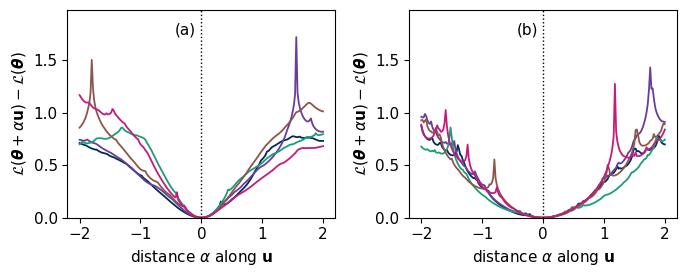

In [14]:
def loss_cuts(nll_m, theta_c, c, n_dir=5, half_width=2.0, n_grid=201, seed=0):
    # loss along n_dir random unit directions u through theta_c: L(theta_c + alpha u) - L(theta_c)
    a = np.linspace(-half_width, half_width, n_grid)
    rng = np.random.default_rng(seed)
    cuts = []
    for _ in range(n_dir):
        u = rng.normal(size=theta_c.size); u /= np.linalg.norm(u)
        line = jnp.asarray(theta_c[None, :] + a[:, None] * u[None, :])
        cuts.append(np.asarray(jax.vmap(lambda th: nll_m(th, c))(line)) - float(nll_m(jnp.asarray(theta_c), c)))
    return a, np.array(cuts)

def count_minima(v):
    # minima along a one-dimensional cut: grid points lower than both neighbours, without a threshold on the depth
    return int(np.sum((v[1:-1] < v[:-2]) & (v[1:-1] < v[2:])))

t0 = time.perf_counter()
a_cut, cuts_xyz = loss_cuts(nll, np.asarray(theta_true), counts)
P4c, born4c, probes4c, _ = make_experiment(pxp_terms(4), 4, seed=104, blockade=True)
nll4c = jax.jit(make_nll(born4c))
theta4c = np.asarray(jax.random.uniform(jax.random.PRNGKey(4), (4,), minval=-1, maxval=1))
key, k = jax.random.split(key)
counts4c = sample_counts(k, born4c(jnp.asarray(theta4c)), M_P)
_, cuts_pxp = loss_cuts(nll4c, theta4c, counts4c)
t_land = time.perf_counter() - t0
minima = {"XYZ": [count_minima(v) for v in cuts_xyz], "PXP": [count_minima(v) for v in cuts_pxp]}
print(f"loss along 5 random directions, alpha in [-2, 2], in {t_land:.1f} s")
print("local minima per cut:", minima, "| medians:", {k_: int(np.median(v)) for k_, v in minima.items()},
      "| ranges:", {k_: (min(v), max(v)) for k_, v in minima.items()})

def sharpest_peak(born_m, theta_c, c, cuts, names, seed=0):
    # the grid point that rises most above its two neighbours, and the recorded shots to which the model gives a probability below 1e-3 there
    exc = cuts[:, 1:-1] - 0.5 * (cuts[:, :-2] + cuts[:, 2:])
    j, k = np.unravel_index(np.argmax(exc), exc.shape); k += 1
    rng = np.random.default_rng(seed)
    for _ in range(j + 1):
        u = rng.normal(size=theta_c.size); u /= np.linalg.norm(u)           # the same directions as in loss_cuts
    th = theta_c + a_cut[k] * u
    p = np.asarray(born_m(jnp.asarray(th))); cn = np.asarray(c)
    rare = (p < 1e-3) & (cn > 0)
    share = float(-(cn[rare] * np.log(p[rare] + 1e-300)).sum() / cn.sum())
    return dict(cut=int(j), alpha=float(a_cut[k]), height=float(cuts[j, k]), rise=float(exc[j, k - 1]), coefficients=np.round(th, 3).tolist(), nearest_zero=names[int(np.argmin(np.abs(th)))],
                smallest_probability=float(p[cn > 0].min()), shots_below_1e3=int(cn[rare].sum()), loss_from_these_shots=share)
PEAKS = {"XYZ": sharpest_peak(born, np.asarray(theta_true), counts, cuts_xyz, NAMES),
         "PXP": sharpest_peak(born4c, theta4c, counts4c, cuts_pxp, list(pxp_terms(4)))}
for k_, d_ in PEAKS.items():
    print(f"sharpest peak, {k_}: cut {d_['cut']}, alpha = {d_['alpha']:+.2f}, height {d_['height']:.2f} ({d_['rise']:.2f} above its neighbours), coefficients {d_['coefficients']}, closest to zero: {d_['nearest_zero']};")
    print(f"    smallest model probability of a recorded string {d_['smallest_probability']:.1e}; {d_['shots_below_1e3']} shots have strings with model probability "
          f"below 1e-3 and contribute {d_['loss_from_these_shots']:.2f} to the loss")
NUMBERS.update(MinimaXYZ=f"{int(np.median(minima['XYZ']))}", MinimaPXP=f"{int(np.median(minima['PXP']))}")

y_top = 1.15 * max(cuts_xyz.max(), cuts_pxp.max())
def cut_drawer(v, ylab):
    def draw(ax):
        for j in range(v.shape[0]):
            ax.plot(a_cut, v[j], color=COEF_COL[j], lw=1.3)
        ax.axvline(0, color=COL["exact"], ls=":", lw=1)
        ax.set_ylim(0, y_top); ax.set_xlabel(r"distance $\alpha$ along $\mathbf{u}$")
        ax.set_ylabel(r"$\mathcal{L}(\boldsymbol{\theta}+\alpha\mathbf{u})-\mathcal{L}(\boldsymbol{\theta})$" if ylab else "")
    return draw
figure_set("fig_lab077_landscapes", [cut_drawer(cuts_xyz, True), cut_drawer(cuts_pxp, True)], [(0.40, 0.88), (0.40, 0.88)])


The XYZ loss in panel (a) rises steeply on both sides of the true coefficients at $\alpha=0$. The PXP loss in panel (b) stays low out to about $|\alpha|=0.5$ and rises beyond. Both have side minima further out. We count as a minimum along a cut every grid point whose loss is lower than at its two neighbours, without a threshold on its depth. The five cuts of the XYZ loss contain between 2 and 8 such minima (median 6), and those of the PXP loss between 9 and 18 (median 12), most of them shallow ripples away from the centre. A minimum along a one-dimensional cut indicates a possible trap, but it need not be a minimum of the loss in all four or five coefficients, so the counts describe the roughness of these cuts and do not predict the success rates above. The printed lines document the origin of the sharp peaks for the sharpest one of each panel. The peaks sit at the values of $\alpha$ at which one coefficient of the cut passes through zero, the field $h_x$ in panel (a) and the Rabi frequency $\Omega_3$ in panel (b). A model without this term forbids outcomes that the record contains. An atom with $\Omega_i=0$, for instance, never flips. The model probability of several thousand recorded shots then falls below $10^{-3}$, and their logarithms dominate the loss. The peaks are narrow logarithmic singularities of the likelihood, and the grid of 201 points cuts them off. The published figure below compares the loss landscapes of three models in Ref. [1], with the plain model in the top row.

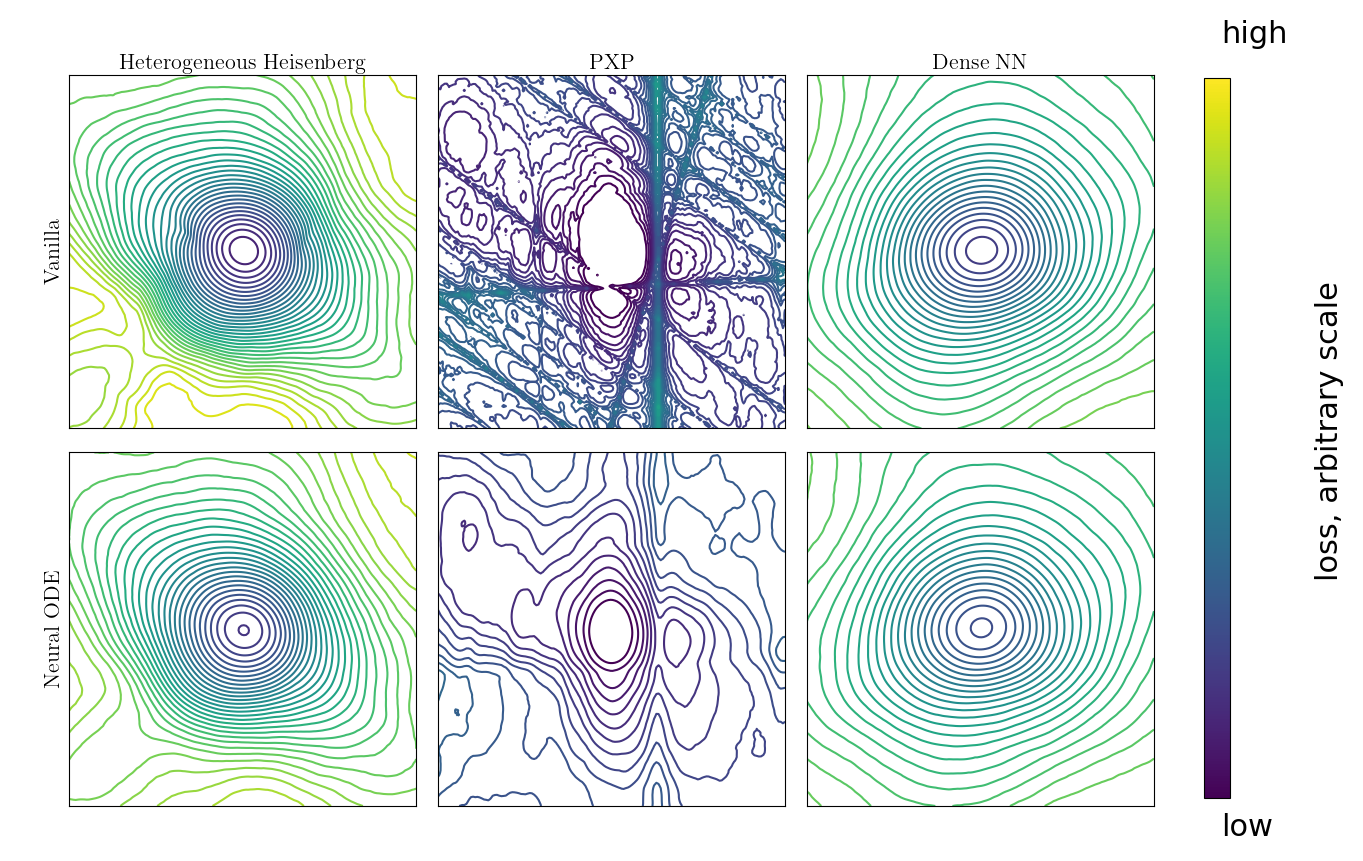

*Reproduced from arXiv:2408.08639v1 (Ref. [1]), Fig. 4. Loss landscapes in a plane spanned by two random directions through the global minimum (centre) for an anisotropic Heisenberg chain with site-dependent couplings, the PXP model and a model with all two-body nearest-neighbour terms (columns, from left to right). The column title "Dense NN" of the source stands for nearest neighbours and has no relation to a neural network. The top row shows the plain model of Sections 4 and 5 and the bottom row the neural differential equation of Section 11. Contours are coloured from low loss (dark) to high loss (light), and the colour scale is arbitrary because the published figure gives no tick values.*

### 10.1 Background on other kinds of data

This subsection is background and is not used in the rest of the notebook. Time-resolved data are one of several kinds of data from which a Hamiltonian can be learned, and the sketch compares three others. A stationary state, such as an eigenstate or a steady state, satisfies $\langle i[\hat{\mathcal H},\hat O_a]\rangle=0$ for every observable $\hat O_a$. With $\hat{\mathcal H}=\sum_j\theta_j\hat P_j$ this is the linear system $B\boldsymbol\theta=0$ with the measured matrix $B_{aj}=\langle i[\hat P_j,\hat O_a]\rangle$, so the coefficients span the null space of $B$ [15,16]. A thermal state $e^{-\beta\hat{\mathcal H}}/Z$ fixes the coefficients through its local expectation values [17], and expectation values measured shortly after a quench rise with initial slopes that are linear in the coefficients [18].

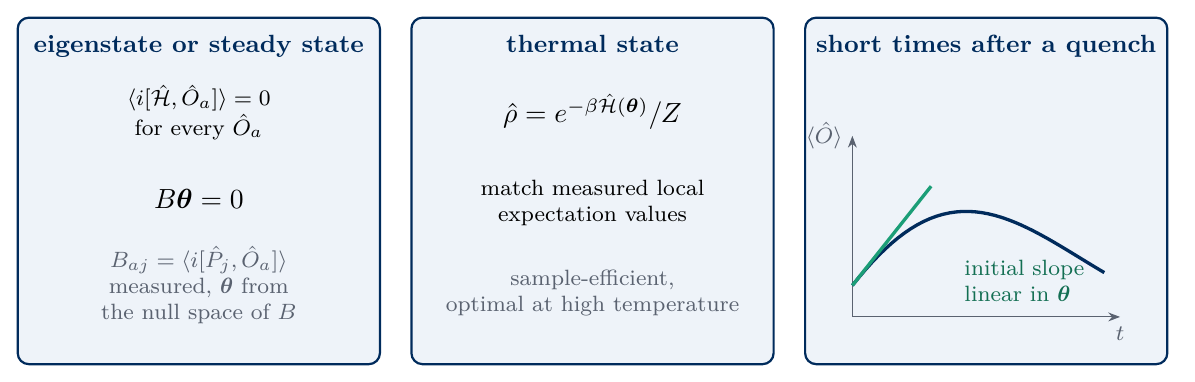

*Three further routes to the coefficients. A stationary state gives a linear system for them, a thermal state ties them to measured local expectation values, and short times after a quench give initial slopes that are linear in them.*

## 11. Neural differential equations

This section is for work at home and takes about 45 s for Section 11.1 and about 20 s for each of the two cells of Section 11.2. A neural ordinary differential equation [23] is a differential equation whose right-hand side contains a neural network, and it is trained by differentiating through the numerical solver. Ref. [1] adds such a network to the Schrödinger equation of the assumed Hamiltonian $\hat{\mathcal H}_A(\boldsymbol\theta)$,
$$i\frac{d}{dt}|\psi(t)\rangle=\hat{\mathcal H}_A(\boldsymbol\theta)|\psi(t)\rangle+\mathrm{NN}_{\boldsymbol\phi}\big(|\psi(t)\rangle\big) , \tag{17}$$
where $\mathrm{NN}_{\boldsymbol\phi}$ maps the state vector to a correction vector and has its own parameters $\boldsymbol\phi$. The coefficients $\boldsymbol\theta$ keep their physical meaning, and the network can represent dynamics that the assumed form misses. Our network takes the $2\cdot2^N$ real and imaginary parts of the amplitudes, passes them through one hidden layer of 32 units with $\tanh$ activation and returns $2\cdot2^N$ numbers that form a complex vector. The correction need not conserve the norm, so the state is normalised before the Born rule (4). The network makes the right-hand side nonlinear, so equation (17) is integrated with the fourth-order Runge–Kutta method [10], which for $\dot\psi=f(\psi)$ and a step $h$ reads
$$\psi(t+h)=\psi(t)+\frac h6\big(k_1+2k_2+2k_3+k_4\big),\quad k_1=f(\psi),\ k_2=f\big(\psi+\tfrac h2k_1\big),\ k_3=f\big(\psi+\tfrac h2k_2\big),\ k_4=f(\psi+hk_3) , \tag{18}$$
with $h=0.05$, four steps per interval $\Delta t=0.2$. The loss is the negative log-likelihood (5) plus a penalty $\lambda\sum\phi^2$ on the size of the network parameters, with $\lambda=10^{-4}$, which keeps the correction small.

Training follows the curriculum of Ref. [1] in the sketch. A warm-up trains $\boldsymbol\theta$ and $\boldsymbol\phi$ together. During the warm-up the network can supply dynamics that coefficients far from their true values fail to produce, so the model fits the data while $\boldsymbol\theta$ is still far from the truth, and the coefficients are led through the regions in which the plain loss is rugged. The network is then switched off in the forward and backward pass, which turns equation (17) back into the plain model, and only $\boldsymbol\theta$ is trained. Finally $\boldsymbol\theta$ is frozen and only the network is trained, so that it absorbs what the assumed Hamiltonian cannot describe. Section 11.2 tests whether the size of this final correction indicates how incomplete the assumed form is.

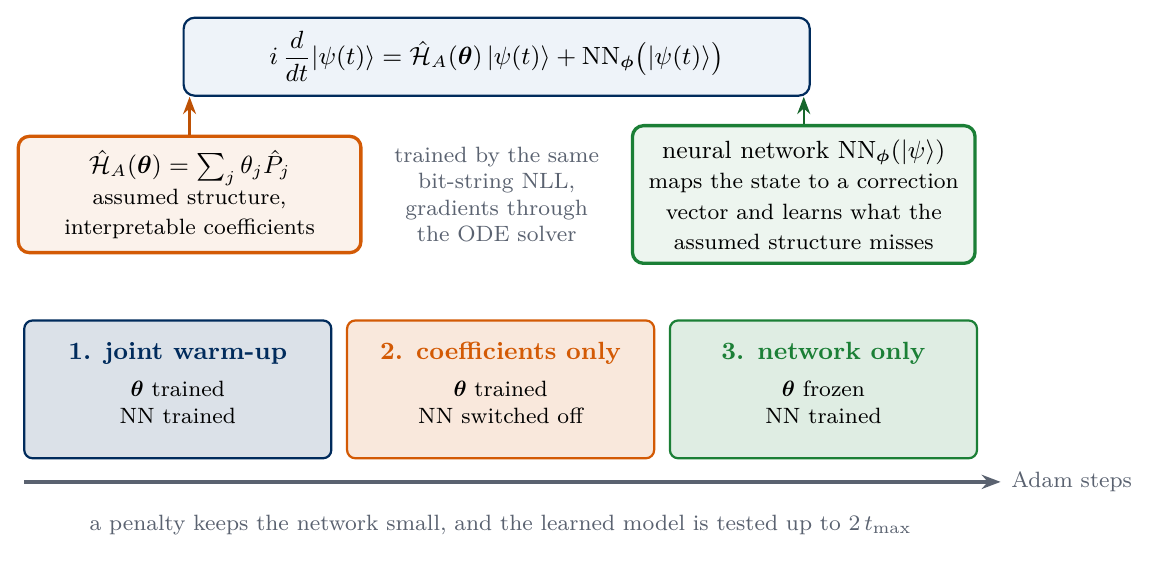

*Neural differential equation for Hamiltonian learning. The assumed Hamiltonian and a neural network share the right-hand side of the Schrödinger equation, and training proceeds in three phases.*

### 11.1 The warm-up and the success rate

We test whether the warm-up repairs the fit of the PXP model, with four atoms and the 16 problems of Section 10. Every problem is fitted three times from the same start. The plain model runs 1500 Adam steps. The curriculum runs the warm-up for 500 steps and then the plain model for 1000 steps. A control follows the same schedule without the network, with 500 steps of the plain model, a restart of Adam and 1000 further steps, and shows whether the restart of the optimiser alone changes the result. All three use the Runge–Kutta integrator. In the warm-up the step size is $0.05$ for $\boldsymbol\theta$ and $3\times10^{-3}$ for $\boldsymbol\phi$, so the network adapts slowly. The cell prints the success counts and describes where the plain fits end, by the number of Rabi frequencies with the wrong sign, the relative error (7) of their magnitudes $|\Omega_i|$ and the final loss. Its first figure shows the success rates. Its second figure shows, for the first of the 16 problems, the four Rabi frequencies against the Adam step for the plain model and for the curriculum.

PXP, N = 4, 16 problems (23.3 s)
  plain model, 1500 steps          : success 0 of 16
  plain 500 + restart + plain 1000 : success 0 of 16  (control, no network)
  warm-up 500 + plain model 1000   : success 16 of 16
  plain model    : wrong signs per problem [1 3 2 1 2 1 2 2 1 2 2 3 2 2 2 2]
                   relative error of the magnitudes: median 0.47, range 0.11 to 1.39, below 0.1 in 0 of 16;  final NLL 1.96 to 2.86
  control        : wrong signs per problem [1 3 2 1 2 1 2 2 1 2 2 3 2 2 2 2]
                   relative error of the magnitudes: median 0.43, range 0.11 to 1.39, below 0.1 in 0 of 16;  final NLL 1.96 to 2.86
  warm-up + plain: wrong signs per problem [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0]
                   relative error of the magnitudes: median 0.01, range 0.00 to 0.03, below 0.1 in 16 of 16;  final NLL 1.88 to 1.95
  final NLL of the plain model minus that of the curriculum, per problem: 0.04 to 0.91
  problem 0: true Omega [ 0.083 -0.417 -0.565 -0.801] | plain model [

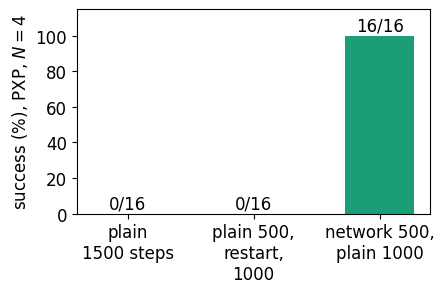

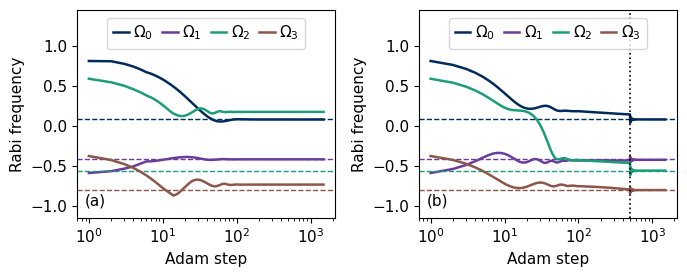

In [15]:
# work at home, about 45 s on a laptop CPU
def init_nn(key, d, hidden=32):
    k1_, k2_ = jax.random.split(key)
    return dict(W1=jax.random.normal(k1_, (2 * d, hidden)) / np.sqrt(2 * d), b1=jnp.zeros(hidden),
                W2=0.1 * jax.random.normal(k2_, (hidden, 2 * d)) / np.sqrt(hidden), b2=jnp.zeros(2 * d))

def nn_apply(phi, psi):
    # NN_phi(psi): real and imaginary parts in, complex correction vector out
    d = psi.shape[-1]
    x = jnp.concatenate([psi.real, psi.imag], axis=-1)
    y = jnp.tanh(x @ phi["W1"] + phi["b1"]) @ phi["W2"] + phi["b2"]
    return y[..., :d] + 1j * y[..., d:]

def node_trajectory(theta, phi, on, P, probes, k_times, dt=DT_P, substeps=4):
    # equation (17) integrated with the Runge-Kutta steps (18); on = 0 switches the network off
    H = hamiltonian(theta, P)
    if phi is None:                                             # plain model, no network parameters at all
        f = lambda psi: -1j * (psi @ H.T)
    else:
        f = lambda psi: -1j * (psi @ H.T + on * nn_apply(phi, psi))
    h = dt / substeps
    def rk4(psi, _):
        k1_ = f(psi); k2_ = f(psi + h / 2 * k1_); k3_ = f(psi + h / 2 * k2_); k4_ = f(psi + h * k3_)
        return psi + h / 6 * (k1_ + 2 * k2_ + 2 * k3_ + k4_), None
    def interval(psi, _):
        psi, _ = jax.lax.scan(rk4, psi, None, length=substeps)
        return psi, psi
    return jax.lax.scan(interval, probes, None, length=k_times)[1]          # [time, probe, amplitude]

def born_from_trajectory(traj, u_bases):
    traj = traj / jnp.linalg.norm(traj, axis=-1, keepdims=True)
    return jnp.abs(jnp.einsum("gab,kpb->pgka", u_bases, traj)) ** 2

LAMBDA_NN, LR_NN = 1e-4, 3e-3
def l2(phi): return sum(jnp.sum(v ** 2) for v in jax.tree_util.tree_leaves(phi))

N4 = 4
P4, born4, probes4_bits, PROBES4 = make_experiment(pxp_terms(N4), N4, seed=100 + N4, blockade=True)
UB4 = basis_rotations(N4)
# the Runge-Kutta model without network reproduces the exact exponential
th_chk = jnp.array([0.3, -0.7, 0.5, 0.9])
assert np.allclose(born_from_trajectory(node_trajectory(th_chk, None, 0.0, P4, PROBES4, K_P), UB4), born4(th_chk), atol=1e-8)

def nll_node(theta, phi, on, c, k_times=K_P):
    p = born_from_trajectory(node_trajectory(theta, phi, on, P4, PROBES4, k_times), UB4)
    return -jnp.sum(c * jnp.log(p + 1e-300)) / jnp.sum(c)

def plain_rk(th0, c):
    # plain model; returns the final coefficients and their values after every step
    return adam(lambda th: nll_node(th, None, 0.0, c), th0, 0.05, 1500, record=lambda q: q)

def plain_restart(th0, c):
    # control: the same 500 + 1000 steps with Adam restarted at step 500, network switched off throughout
    th = adam(lambda q: nll_node(q, None, 0.0, c), th0, 0.05, 500)[0]
    return adam(lambda q: nll_node(q, None, 0.0, c), th, 0.05, 1000)[0]

def warmup_then_theta(th0, c, key_nn):
    phi0 = init_nn(key_nn, 2 ** N4)
    lrs = (0.05, tmap(lambda x: LR_NN, phi0))
    (th, phi), path1 = adam(lambda q: nll_node(q[0], q[1], 1.0, c) + LAMBDA_NN * l2(q[1]), (th0, phi0), lrs, 500, record=lambda q: q[0])
    th, path2 = adam(lambda q: nll_node(q, None, 0.0, c), th, 0.05, 1000, record=lambda q: q)
    return th, jnp.concatenate([path1, path2])                 # final coefficients and their values after every step

# the same 16 problems as for PXP, N = 4 in Section 10
k_true, k_start, k_data = jax.random.split(jax.random.PRNGKey(100 + N4), 3)
truths4 = jax.random.uniform(k_true, (RUNS, N4), minval=-1, maxval=1)
starts4 = jax.random.uniform(k_start, (RUNS, N4), minval=-1, maxval=1)
data4 = jax.vmap(lambda kk, th: sample_counts(kk, born4(th), M_P))(jax.random.split(k_data, RUNS), truths4)
t0 = time.perf_counter()
fit_v, path_v = map(np.asarray, jax.jit(jax.vmap(plain_rk))(starts4, data4))
fit_w, path_w = map(np.asarray, jax.jit(jax.vmap(warmup_then_theta))(starts4, data4, jax.random.split(jax.random.PRNGKey(41), RUNS)))
fit_c = np.asarray(jax.jit(jax.vmap(plain_restart))(starts4, data4))
t_node_success = time.perf_counter() - t0
err_v = np.abs(fit_v - np.asarray(truths4)).sum(1) / np.abs(np.asarray(truths4)).sum(1)
err_w = np.abs(fit_w - np.asarray(truths4)).sum(1) / np.abs(np.asarray(truths4)).sum(1)
err_c = np.abs(fit_c - np.asarray(truths4)).sum(1) / np.abs(np.asarray(truths4)).sum(1)
print(f"PXP, N = 4, {RUNS} problems ({t_node_success:.1f} s)")
print(f"  plain model, 1500 steps          : success {int(np.sum(err_v < 0.1))} of {RUNS}")
print(f"  plain 500 + restart + plain 1000 : success {int(np.sum(err_c < 0.1))} of {RUNS}  (control, no network)")
print(f"  warm-up 500 + plain model 1000   : success {int(np.sum(err_w < 0.1))} of {RUNS}")

# where the fits end: Rabi frequencies with the wrong sign, relative error (7) of the magnitudes |Omega_i|, final loss of the plain model
truths4_np = np.asarray(truths4)
final_nll4 = jax.jit(jax.vmap(lambda th, c: nll_node(th, None, 0.0, c)))
ENDS = {}
for name_, fit_ in (("plain model", fit_v), ("control", fit_c), ("warm-up + plain", fit_w)):
    wrong = np.sum(np.sign(fit_) != np.sign(truths4_np), axis=1)
    err_abs = np.abs(np.abs(fit_) - np.abs(truths4_np)).sum(1) / np.abs(truths4_np).sum(1)
    loss_ = np.asarray(final_nll4(jnp.asarray(fit_), data4))
    ENDS[name_] = dict(wrong_signs=wrong.tolist(), err_magnitudes=err_abs.tolist(), final_nll=loss_.tolist())
    print(f"  {name_:15s}: wrong signs per problem {wrong}")
    print(f"  {'':15s}  relative error of the magnitudes: median {np.median(err_abs):.2f}, range {err_abs.min():.2f} to {err_abs.max():.2f}, below 0.1 in {int(np.sum(err_abs < 0.1))} of {RUNS};"
          f"  final NLL {loss_.min():.2f} to {loss_.max():.2f}")
loss_gap = np.array(ENDS["plain model"]["final_nll"]) - np.array(ENDS["warm-up + plain"]["final_nll"])
print(f"  final NLL of the plain model minus that of the curriculum, per problem: {loss_gap.min():.2f} to {loss_gap.max():.2f}")
print("  problem 0: true Omega", np.round(truths4_np[0], 3), "| plain model", np.round(fit_v[0], 3), "| curriculum", np.round(fit_w[0], 3))
NUMBERS.update(NodeSuccVanilla=f"{int(np.sum(err_v < 0.1))}", NodeSuccControl=f"{int(np.sum(err_c < 0.1))}", NodeSuccWarm=f"{int(np.sum(err_w < 0.1))}")

def draw_node_success(ax):
    errs = (err_v, err_c, err_w)
    ax.bar([0, 1, 2], [100 * np.mean(e < 0.1) for e in errs], color=[COL["navy"], COL["purple"], COL["teal"]], width=0.55)
    for i_, e in enumerate(errs):
        ax.text(i_, 100 * np.mean(e < 0.1) + 3, f"{int(np.sum(e < 0.1))}/{RUNS}", ha="center")
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["plain\n1500 steps", "plain 500,\nrestart,\n1000", "network 500,\nplain 1000"])
    ax.set_ylabel("success (%), PXP, $N=4$"); ax.set_ylim(0, 115)
figure_single("fig_lab077_node_success", draw_node_success)

OMEGA_LABEL = [fr"$\Omega_{i_}$" for i_ in range(N4)]
def path_drawer(path, mark_switch):
    def draw(ax):
        for j in range(N4):
            ax.plot(np.arange(1, path.shape[0] + 1), path[:, j], color=COEF_COL[j], lw=1.8, label=OMEGA_LABEL[j])
            ax.axhline(truths4_np[0, j], color=COEF_COL[j], ls="--", lw=1)
        if mark_switch:
            ax.axvline(500, color=COL["exact"], ls=":", lw=1.2)                 # the network is switched off after step 500
        ax.set_xscale("log"); ax.set_xlabel("Adam step"); ax.set_ylabel("Rabi frequency"); ax.set_ylim(-1.15, 1.45)
        ax.legend(loc="upper center", ncol=4, columnspacing=0.6, handlelength=1.0, handletextpad=0.3)
    return draw
figure_set("fig_lab077_node_paths", [path_drawer(path_v[0], False), path_drawer(path_w[0], True)], [(0.03, 0.06), (0.03, 0.06)])


The plain model with 1500 Adam steps succeeds in none of the 16 problems, and the control with the restart of Adam also succeeds in none. The warm-up with the network followed by the plain model succeeds in all 16. The network is switched off before the final fit, so the reported coefficients come from the plain model alone. Since the control has the same restart and the same number of steps, the improvement comes from the network during the warm-up.

In every problem the plain fit ends with between one and three of the four Rabi frequencies at the wrong sign. The magnitudes are wrong as well, with a relative error between $0.11$ and $1.39$ (median $0.47$), so the plain fits do not sit at one of the sign patterns that the $Z$ data cannot distinguish. Their final loss lies between $0.04$ and $0.91$ nats per shot above that of the curriculum, which identifies them as local minima. The second figure follows the first problem, and in its panel (a) the plain fit settles within about 100 steps with $\Omega_2$ at a positive value, although its true value is negative, and stays there. In panel (b), from the same start, $\Omega_2$ changes sign during the warm-up, and when the network is switched off at step 500, the dotted line, all four frequencies lie within about $0.15$ of their true values, from where the plain model of the second phase converges to them. This path agrees with the purpose of the warm-up stated above, in which the network fits the data while the coefficients are still far from the truth and so leads them through the rugged regions of the plain loss, and with the smoother landscapes in the bottom row of the published figure. Our runs record the path of the coefficients and do not test the mechanism further. The published rates in the second figure of Section 10 show the same contrast up to eight spins. The plain model, dashed lines, fails increasingly often for the PXP model, while the neural differential equation, solid lines, succeeds in almost every problem.

### 11.2 A term missing from the model

A real Rydberg chain also has a weaker interaction between next-nearest neighbours, which the PXP model (16) leaves out. We simulate the device with
$$\hat{\mathcal H}_{\mathrm{true}}=\hat{\mathcal H}_{\mathrm{PXP}}(\boldsymbol\Omega)+V_2\sum_{i=0}^{N-3}\hat n_i\hat n_{i+2},\qquad\hat n=|1\rangle\langle1| , \tag{19}$$
with $V_2=0.4$, and fit the PXP model with the network of equation (17). The training data cover the times up to $t_{\max}=1$, and we test the learned models on fresh bit strings at times up to $2t_{\max}$. The three phases have 500, 800 and 1500 Adam steps. Of four random starts we keep the one whose plain model reaches the lowest loss after the second phase, a choice made from the data alone. Two of the four starts reach this lowest loss and the other two end slightly higher. We test the plain model with the fitted $\tilde{\boldsymbol\Omega}$ and the same model with the trained network switched on. The test uses the negative log-likelihood of the test bit strings at each time and, in the simulation only, the fidelity
$$F(t)=\big|\langle\psi_{\mathrm{true}}(t)|\psi_{\mathrm{model}}(t)\rangle\big|^2 \tag{20}$$
with the state of the simulated device, averaged over the three probes.

The first cell runs the curriculum on this record. The second cell repeats it, with the same four starts, for a record generated without the missing term, $V_2=0$, for which the PXP model is complete. This reference shows which size of correction and which change of the test likelihood the network produces when nothing is missing.

curriculum, 4 starts, 2800 steps each: 10.5 s; plain-model loss after phase 2 per start: [1.9029 1.9149 1.9014 1.9014]
true Omega   : {'Omega0': -0.7429, 'Omega1': -0.0014, 'Omega2': 0.203, 'Omega3': -0.9426}
fitted Omega : {'Omega0': -0.734, 'Omega1': 0.0032, 'Omega2': 0.2047, 'Omega3': -0.9328} | relative error 0.013
mean size of the network correction |NN(psi)| along the trajectory: 0.231
time              : [0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2. ]
1 - F plain model : [0.     0.0005 0.0021 0.0058 0.0117 0.0193 0.0272 0.0339 0.0382 0.0398]
1 - F with network: [0.0004 0.0008 0.0009 0.0012 0.0027 0.0069 0.0155 0.0295 0.0495 0.075 ]
test NLL excess, plain  : [-0.     -0.0001  0.002   0.0051  0.0116  0.0163  0.0192  0.0287  0.034
  0.035 ]
test NLL excess, network: [0.     0.0008 0.0011 0.0011 0.0031 0.0068 0.0171 0.0248 0.0457 0.069 ]
reduction of the test NLL per shot by the network, mean over t <= t_max: +0.0025


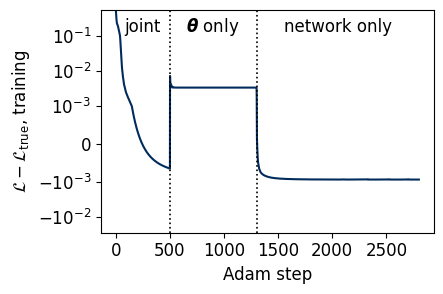

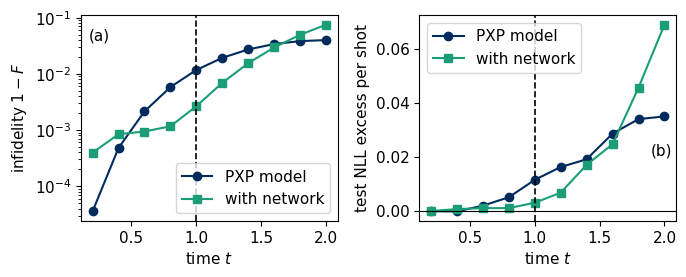

In [16]:
# work at home, about 20 s on a laptop CPU
V2 = 0.4
NNN4 = jnp.asarray(sum(op(N4, {i: N_RYD, i + 2: N_RYD}) for i in range(N4 - 2)))
K_TEST = 2 * K_P
omega_true = jnp.asarray(np.random.default_rng(11).uniform(-1, 1, N4))
U_true = expm_taylor(-1j * DT_P * (hamiltonian(omega_true, P4) + V2 * NNN4))
traj_true = jax.lax.scan(lambda p, _: (p @ U_true.T, p @ U_true.T), PROBES4, None, length=K_TEST)[1]
p_true4 = born_from_trajectory(traj_true, UB4)
key, k_tr, k_te = jax.random.split(key, 3)
c_train = sample_counts(k_tr, p_true4[:, :, :K_P], M_P)
c_test = sample_counts(k_te, p_true4, M_P)

PH = (500, 800, 1500)
def make_curriculum(c_tr):
    # the three phases of the curriculum for the training record c_tr
    @jax.jit
    def curriculum(th0, key_nn):
        phi0 = init_nn(key_nn, 2 ** N4)
        reg = lambda th, phi: nll_node(th, phi, 1.0, c_tr) + LAMBDA_NN * l2(phi)
        (th1, phi1), h1 = adam(lambda q: reg(q[0], q[1]), (th0, phi0), (0.05, tmap(lambda x: LR_NN, phi0)), PH[0])
        th2, h2 = adam(lambda q: nll_node(q, phi1, 0.0, c_tr), th1, 0.02, PH[1])                 # network switched off
        phi3, h3 = adam(lambda q: reg(th2, q), phi1, tmap(lambda x: LR_NN, phi1), PH[2])         # theta frozen
        return th1, th2, phi3, jnp.concatenate([h1, h2, h3])
    return curriculum
curriculum = make_curriculum(c_train)

t0 = time.perf_counter()
starts_c = jax.random.uniform(jax.random.PRNGKey(12), (4, N4), minval=-1, maxval=1)
runs_c = [curriculum(starts_c[i], jax.random.PRNGKey(20 + i)) for i in range(4)]
loss_after_2 = [float(nll_node(r[1], None, 0.0, c_train)) for r in runs_c]
best_c = int(np.argmin(loss_after_2))
th_warm, omega_fit, phi_fit, hist_c = runs_c[best_c]
t_curr = time.perf_counter() - t0

def per_time_nll(p):
    return np.asarray(-jnp.sum(c_test * jnp.log(p + 1e-300), axis=(0, 1, 3)) / jnp.sum(c_test, axis=(0, 1, 3)))
traj_plain = node_trajectory(omega_fit, phi_fit, 0.0, P4, PROBES4, K_TEST)
traj_nn = node_trajectory(omega_fit, phi_fit, 1.0, P4, PROBES4, K_TEST)
L_ref, L_plain, L_nn = per_time_nll(p_true4), per_time_nll(born_from_trajectory(traj_plain, UB4)), per_time_nll(born_from_trajectory(traj_nn, UB4))
def fidelity(traj):
    tr = traj / jnp.linalg.norm(traj, axis=-1, keepdims=True)
    return np.asarray(jnp.mean(jnp.abs(jnp.sum(traj_true.conj() * tr, axis=-1)) ** 2, axis=1))
F_plain, F_nn = fidelity(traj_plain), fidelity(traj_nn)
nn_size = float(jnp.mean(jnp.linalg.norm(nn_apply(phi_fit, traj_nn), axis=-1)))
omega_err = float(np.abs(np.asarray(omega_fit) - np.asarray(omega_true)).sum() / np.abs(np.asarray(omega_true)).sum())
T_TEST = DT_P * np.arange(1, K_TEST + 1)
print(f"curriculum, 4 starts, {sum(PH)} steps each: {t_curr:.1f} s; plain-model loss after phase 2 per start: {np.round(loss_after_2, 4)}")
print("true Omega   :", named(omega_true, list(pxp_terms(N4))))
print("fitted Omega :", named(omega_fit, list(pxp_terms(N4))), f"| relative error {omega_err:.3f}")
print(f"mean size of the network correction |NN(psi)| along the trajectory: {nn_size:.3f}")
print("time              :", np.round(T_TEST, 1))
print("1 - F plain model :", np.round(1 - F_plain, 4))
print("1 - F with network:", np.round(1 - F_nn, 4))
print("test NLL excess, plain  :", np.round(L_plain - L_ref, 4))
print("test NLL excess, network:", np.round(L_nn - L_ref, 4))
gain_train = float(np.mean((L_plain - L_nn)[:K_P]))            # reduction of the test NLL by the network, mean over the times up to t_max
print(f"reduction of the test NLL per shot by the network, mean over t <= t_max: {gain_train:+.4f}")
assert omega_err < 0.1
NUMBERS.update(MissingOmegaErr=f"{omega_err:.3f}", InfidPlainTmax=sci(1 - F_plain[K_P - 1]), InfidNNTmax=sci(1 - F_nn[K_P - 1]),
               InfidPlainTwoTmax=sci(1 - F_plain[-1]), InfidNNTwoTmax=sci(1 - F_nn[-1]), VTwo=f"{V2}")

steps_axis = np.arange(1, sum(PH) + 1)
L_train_true = float(-jnp.sum(c_train * jnp.log(p_true4[:, :, :K_P] + 1e-300)) / jnp.sum(c_train))   # simulation-only reference
def draw_curriculum(ax):
    ax.plot(steps_axis, np.asarray(hist_c) - L_train_true, color=COL["navy"], lw=1.5)
    for b in np.cumsum(PH)[:-1]:
        ax.axvline(b, color=COL["exact"], ls=":", lw=1.2)
    for x_, lab in zip((PH[0] / 2, PH[0] + PH[1] / 2, PH[0] + PH[1] + PH[2] / 2), ("joint", r"$\boldsymbol{\theta}$ only", "network only")):
        ax.text(x_, 0.9, lab, ha="center", transform=ax.get_xaxis_transform())
    ax.set_yscale("symlog", linthresh=1e-3); ax.set_xlabel("Adam step"); ax.set_ylabel(r"$\mathcal{L}-\mathcal{L}_{\mathrm{true}}$, training")
figure_single("fig_lab077_curriculum", draw_curriculum)

def draw_extra_a(ax):
    ax.semilogy(T_TEST, 1 - F_plain, "o-", color=COL["navy"], ms=6, lw=1.5, label="PXP model")
    ax.semilogy(T_TEST, 1 - F_nn, "s-", color=COL["teal"], ms=6, lw=1.5, label="with network")
    ax.axvline(DT_P * K_P, color=COL["exact"], ls="--", lw=1.2); ax.set_xlabel(r"time $t$")
    ax.set_ylabel(r"infidelity $1-F$"); ax.legend(loc="lower right")

def draw_extra_b(ax):
    ax.plot(T_TEST, L_plain - L_ref, "o-", color=COL["navy"], ms=6, lw=1.5, label="PXP model")
    ax.plot(T_TEST, L_nn - L_ref, "s-", color=COL["teal"], ms=6, lw=1.5, label="with network")
    ax.axhline(0, color=COL["exact"], lw=0.8); ax.axvline(DT_P * K_P, color=COL["exact"], ls="--", lw=1.2)
    ax.set_xlabel(r"time $t$"); ax.set_ylabel(r"test NLL excess per shot"); ax.legend(loc="upper left")
figure_set("fig_lab077_extrapolation", [draw_extra_a, draw_extra_b], [(0.03, 0.88), (0.90, 0.32)])

In [17]:
# work at home, about 20 s on a laptop CPU: the same curriculum for a record without the missing term (V2 = 0)
t0 = time.perf_counter()
U_ref = expm_taylor(-1j * DT_P * hamiltonian(omega_true, P4))
traj_ref = jax.lax.scan(lambda p, _: (p @ U_ref.T, p @ U_ref.T), PROBES4, None, length=K_TEST)[1]
p_ref4 = born_from_trajectory(traj_ref, UB4)
k_tr0, k_te0 = jax.random.split(jax.random.PRNGKey(770))                  # separate key, so the random numbers of the other cells stay unchanged
c_train0 = sample_counts(k_tr0, p_ref4[:, :, :K_P], M_P)
c_test0 = sample_counts(k_te0, p_ref4, M_P)
curriculum0 = make_curriculum(c_train0)
runs_0 = [curriculum0(starts_c[i], jax.random.PRNGKey(20 + i)) for i in range(4)]
loss_after_2_0 = [float(nll_node(r[1], None, 0.0, c_train0)) for r in runs_0]
best_0 = int(np.argmin(loss_after_2_0))
_, omega_fit0, phi_fit0, _ = runs_0[best_0]
def nn_mean_size(theta, phi):
    # mean norm of the network correction along the trajectories of the three probes up to 2 t_max
    return float(jnp.mean(jnp.linalg.norm(nn_apply(phi, node_trajectory(theta, phi, 1.0, P4, PROBES4, K_TEST)), axis=-1)))
def test_nll0(p):
    return np.asarray(-jnp.sum(c_test0 * jnp.log(p + 1e-300), axis=(0, 1, 3)) / jnp.sum(c_test0, axis=(0, 1, 3)))
L0_plain = test_nll0(born_from_trajectory(node_trajectory(omega_fit0, phi_fit0, 0.0, P4, PROBES4, K_TEST), UB4))
L0_nn = test_nll0(born_from_trajectory(node_trajectory(omega_fit0, phi_fit0, 1.0, P4, PROBES4, K_TEST), UB4))
nn_size0 = nn_mean_size(omega_fit0, phi_fit0)
assert abs(nn_mean_size(omega_fit, phi_fit) - nn_size) < 1e-12                 # the same definition as in the previous cell
sizes_V2 = [nn_mean_size(r[1], r[2]) for r in runs_c]; sizes_0 = [nn_mean_size(r[1], r[2]) for r in runs_0]
omega_err0 = float(np.abs(np.asarray(omega_fit0) - np.asarray(omega_true)).sum() / np.abs(np.asarray(omega_true)).sum())
gain_train0 = float(np.mean((L0_plain - L0_nn)[:K_P]))
t_base = time.perf_counter() - t0
print(f"reference without the missing term, 4 starts: {t_base:.1f} s; plain-model loss after phase 2 per start: {np.round(loss_after_2_0, 4)}")
print(f"fitted Omega, relative error {omega_err0:.3f}")
print(f"mean size of the network correction: V2 = 0: {nn_size0:.3f} (four starts {np.round(sizes_0, 3)});  V2 = {V2}: {nn_size:.3f} (four starts {np.round(sizes_V2, 3)})")
print(f"reduction of the test NLL per shot by the network, mean over t <= t_max: V2 = 0: {gain_train0:+.4f};  V2 = {V2}: {gain_train:+.4f}")
print("test NLL, network minus plain model, V2 = 0, per time:", np.round(L0_nn - L0_plain, 4))
NUMBERS.update(NNSizeMissing=f"{nn_size:.2f}", NNSizeComplete=f"{nn_size0:.2f}")
BASELINE = dict(V2=0.0, loss_after_phase2=loss_after_2_0, omega_fit=np.asarray(omega_fit0).tolist(), rel_error=omega_err0, nn_size=nn_size0,
                nn_size_all_starts=sizes_0, nn_size_all_starts_V2=sizes_V2, nll_network_minus_plain=(L0_nn - L0_plain).tolist(),
                nll_gain_train_window=gain_train0, nll_gain_train_window_V2=gain_train, seconds=t_base)

reference without the missing term, 4 starts: 11.7 s; plain-model loss after phase 2 per start: [1.8987 1.8977 1.8977 1.8977]
fitted Omega, relative error 0.007
mean size of the network correction: V2 = 0: 0.189 (four starts [0.193 0.189 0.188 0.189]);  V2 = 0.4: 0.231 (four starts [0.233 0.277 0.231 0.231])
reduction of the test NLL per shot by the network, mean over t <= t_max: V2 = 0: -0.0013;  V2 = 0.4: +0.0025
test NLL, network minus plain model, V2 = 0, per time: [0.0003 0.0018 0.0012 0.0017 0.0015 0.0068 0.0177 0.0307 0.0512 0.0706]


The fitted Rabi frequencies lie within a few percent of the true values although the model lacks the $V_2$ term. The first figure shows the training loss through the three phases relative to the loss of the true Hamiltonian, which only the simulation knows. The curve includes the penalty on the network parameters in the first and third phases. Switching the network off at the start of the second phase raises the loss above the reference. The third phase, in which only the network learns, lowers it slightly below the reference, so the network also fits part of the shot noise of the training record. In panel (a) of the second figure the network reduces the infidelity at $t_{\max}$, the dashed line, about four times. Its infidelity is lower than that of the plain model between about $0.6\,t_{\max}$ and $1.6\,t_{\max}$, and slightly higher at the two earliest times. Beyond this time the model with the network deviates from the device faster, and at $2t_{\max}$ its infidelity is about twice that of the plain model. Panel (b) makes the same comparison from the test bit strings alone, which an experimenter can evaluate, as the excess of the negative log-likelihood per shot over that of the true Hamiltonian. The learned correction is accurate along the training trajectories and becomes harmful beyond them, whereas the error of the plain model grows smoothly because its dynamics is generated by a Hamiltonian. For the reference record without the missing term, computed in the second cell, the same curriculum ends with a correction of mean size $0.19$, against $0.23$ for the record with $V_2=0.4$. Most of the correction is therefore present even when the assumed Hamiltonian is complete, and its size alone does not reveal the missing term. The test likelihood separates the two cases more clearly. Averaged over the times up to $t_{\max}$, the network lowers the test negative log-likelihood by $0.0025$ per shot when the term is missing and raises it by $0.0013$ when the model is complete, where it can only fit the shot noise of the training record. Both comparisons rest on one record for each case. Exercise 7 identifies the term.

## 12. Exercises

1. Replace the $Y$ basis by the complex probe $|{+}i\rangle^{\otimes4}$, keep only $Z$ and $X$ data, and show with the line scan of Section 6 that the minimum at $s=-1$ disappears. The model for the new probe is `make_born(P_STACK, probes, U_BASES[:2], DT, K_TIMES)`, and `sample_counts` draws its record.
2. Show that the transformation $\hat{\mathcal H}\to\hat Z_{\mathrm{all}}\hat{\mathcal H}\hat Z_{\mathrm{all}}$ with $\hat Z_{\mathrm{all}}=\prod_i\hat Z_i$ maps $\hat{\mathcal H}(J_x,J_y,J_z,h_x,h_z)$ of equation (1) to $\hat{\mathcal H}(J_x,J_y,J_z,-h_x,h_z)$. Explain why data in the $Z$ basis from the probes $|0000\rangle$ and $|0101\rangle$ alone cannot determine the sign of $h_x$, check it numerically, and identify which data in Section 3 fix the sign.
3. Compute the Fisher information (10) separately for each of the six times and each basis, and find which configurations contribute most to the bound on $h_z$. Remove the least informative time and compare the bound with the full design at equal total shots. The `einsum` in `fisher_per_shot` sums over all configurations, and the subscripts `"pgkbj,pgkb,pgkbl->gkjl"` keep the basis and the time.
4. Switch off the drive in Section 9 ($\Omega=0$), derive the probabilities from equation (13), and show that $\Gamma$ is then learned from the $Z$ data of the probe $|1\rangle$ alone. Compare the Cramér–Rao bounds with and without drive. The code of Section 9 reads the drive from the variable `H_Q`, which the check of equation (13) sets to zero.
5. Repeat the success-rate measurement of Section 10 for the XYZ chain with five probes in place of three and with 32 problems, and compare the success rate with the 3 of 16 found above. The number of probes is the argument 3 of `rng.choice` in `make_experiment`, and the number of problems is `RUNS`.
6. In Section 11.2 vary $\lambda$ and the width of the hidden layer, and plot the infidelity at $2t_{\max}$ of the model with the network against $\lambda$. The penalty is `LAMBDA_NN` and the width is the argument `hidden` of `init_nn`, and `make_curriculum(c_train)` has to be called again after a change so that the compiled function uses the new values.
7. Add the term $V_2\sum_i\hat n_i\hat n_{i+2}$ with an unknown $V_2$ to the assumed Hamiltonian, fit it with the plain model and compare the extrapolation with the network of Section 11.2. The matrix of the new term is `NNN4`, which can be appended to the stack `P4` as a fifth coefficient.

## 13. Summary

Hamiltonian learning infers the coefficients of a Hamiltonian of known form from bit strings measured after known product states have evolved for chosen times. A differentiable simulation of the same experiment gives the probability of every measured string, the negative log-likelihood of the record is the loss, and automatic differentiation through the matrix exponential gives its gradient. For an anisotropic Heisenberg chain of four qubits the maximum-likelihood estimate reproduces the five coefficients with a relative error of about half a percent from 1000 shots per configuration, for the best of twelve starts on one record. The loss is not convex, so single starts often end in local minima, and the lowest loss among several starts identifies the global minimum from the data alone. The data must also distinguish the coefficients, and real probes measured in real bases cannot distinguish a Hamiltonian $\hat{\mathcal H}$ from $-\hat{\mathcal H}^*$, which for the chain means all coefficients with the opposite sign. The $Y$ basis or a complex probe removes this ambiguity. The error of the estimate falls as the inverse square root of the number of shots and reaches the Cramér–Rao bound set by the Fisher information, which also shows how informative each probe, time and basis is. The same likelihood and gradient learn the decay and dephasing rates of an open qubit once the forward model propagates a density matrix with the Lindblad equation. In our runs a fit from a single random start succeeds in a minority of the problems, in 3 of 16 for the Heisenberg chain and in at most 2 of 16 for the PXP model of Rydberg atoms. These counts do not separate the two models, whereas the success rates published in Ref. [1] are much higher for a Heisenberg chain than for the PXP model. A neural network added to the Schrödinger equation and trained with a warm-up and a staged curriculum raises the success rate for the PXP model with four atoms from 0 to 16 of 16 problems, and the coefficients stay interpretable because the network is switched off before the final fit. The same network absorbs a term missing from the assumed Hamiltonian within the time window of the training data, and its advantage is lost when the model is extrapolated to twice that window. The learned correction is almost as large when no term is missing, so its size alone does not reveal an incomplete model, whereas the likelihood of held-out data improves only when a term is missing.

## References

[1] T. Heightman, E. Jiang, and A. Acín, Solving the quantum many-body Hamiltonian learning problem with neural differential equations, Quantum Sci. Technol. **10**, 045072 (2025), [doi:10.1088/2058-9565/ae0d79](https://doi.org/10.1088/2058-9565/ae0d79). The success rates and the landscape figure are taken from the preprint version [arXiv:2408.08639v1](https://arxiv.org/abs/2408.08639v1) (2024), Table 1 and Fig. 4.

[2] J. Bradbury, R. Frostig, P. Hawkins, M. J. Johnson, C. Leary, D. Maclaurin, G. Necula, A. Paszke, J. VanderPlas, S. Wanderman-Milne and Q. Zhang, JAX: composable transformations of Python+NumPy programs (2018), [github.com/jax-ml/jax](https://github.com/jax-ml/jax).

[3] N. J. Higham, The scaling and squaring method for the matrix exponential revisited, SIAM J. Matrix Anal. Appl. **26**, 1179 (2005), [doi:10.1137/04061101X](https://doi.org/10.1137/04061101X).

[4] D. P. Kingma and J. Ba, Adam: A method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).

[5] H. Cramér, *Mathematical Methods of Statistics* (Princeton University Press, Princeton, 1946), [doi:10.1515/9781400883868](https://doi.org/10.1515/9781400883868).

[6] C. R. Rao, Information and the accuracy attainable in the estimation of statistical parameters, Bull. Calcutta Math. Soc. **37**, 81 (1945), reprinted in *Breakthroughs in Statistics*, edited by S. Kotz and N. L. Johnson (Springer, New York, 1992), p. 235, [doi:10.1007/978-1-4612-0919-5_16](https://doi.org/10.1007/978-1-4612-0919-5_16).

[7] S. L. Braunstein and C. M. Caves, Statistical distance and the geometry of quantum states, Phys. Rev. Lett. **72**, 3439 (1994), [doi:10.1103/PhysRevLett.72.3439](https://doi.org/10.1103/PhysRevLett.72.3439).

[8] G. Lindblad, On the generators of quantum dynamical semigroups, Commun. Math. Phys. **48**, 119 (1976), [doi:10.1007/BF01608499](https://doi.org/10.1007/BF01608499).

[9] V. Gorini, A. Kossakowski, and E. C. G. Sudarshan, Completely positive dynamical semigroups of N-level systems, J. Math. Phys. **17**, 821 (1976), [doi:10.1063/1.522979](https://doi.org/10.1063/1.522979).

[10] E. Hairer, S. P. Nørsett, and G. Wanner, *Solving Ordinary Differential Equations I. Nonstiff Problems*, 2nd ed. (Springer, Berlin, 1993), [doi:10.1007/978-3-540-78862-1](https://doi.org/10.1007/978-3-540-78862-1).

[11] C. E. Granade, C. Ferrie, N. Wiebe, and D. G. Cory, Robust online Hamiltonian learning, New J. Phys. **14**, 103013 (2012), [doi:10.1088/1367-2630/14/10/103013](https://doi.org/10.1088/1367-2630/14/10/103013).

[12] N. Wiebe, C. Granade, C. Ferrie, and D. G. Cory, Hamiltonian learning and certification using quantum resources, Phys. Rev. Lett. **112**, 190501 (2014), [doi:10.1103/PhysRevLett.112.190501](https://doi.org/10.1103/PhysRevLett.112.190501).

[13] J. Wang, S. Paesani, R. Santagati, S. Knauer, A. A. Gentile, N. Wiebe, M. Petruzzella, J. L. O’Brien, J. G. Rarity, A. Laing, and M. G. Thompson, Experimental quantum Hamiltonian learning, Nat. Phys. **13**, 551 (2017), [doi:10.1038/nphys4074](https://doi.org/10.1038/nphys4074).

[14] F. Wilde, A. Kshetrimayum, I. Roth, D. Hangleiter, R. Sweke, and J. Eisert, Scalably learning one-dimensional quantum many-body Hamiltonians from dynamical data, Quantum Sci. Technol. **11**, 035002 (2026), [doi:10.1088/2058-9565/ae6fe3](https://doi.org/10.1088/2058-9565/ae6fe3).

[15] E. Bairey, I. Arad, and N. H. Lindner, Learning a local Hamiltonian from local measurements, Phys. Rev. Lett. **122**, 020504 (2019), [doi:10.1103/PhysRevLett.122.020504](https://doi.org/10.1103/PhysRevLett.122.020504).

[16] X.-L. Qi and D. Ranard, Determining a local Hamiltonian from a single eigenstate, Quantum **3**, 159 (2019), [doi:10.22331/q--159](https://doi.org/10.22331/q--159).

[17] J. Haah, R. Kothari, and E. Tang, Optimal learning of quantum Hamiltonians from high-temperature Gibbs states, Nat. Phys. **20**, 1027 (2024), [doi:10.1038/s41567-023-02376-x](https://doi.org/10.1038/s41567-023-02376-x).

[18] J. Zhang and M. Sarovar, Quantum Hamiltonian identification from measurement time traces, Phys. Rev. Lett. **113**, 080401 (2014), [doi:10.1103/PhysRevLett.113.080401](https://doi.org/10.1103/PhysRevLett.113.080401).

[19] H. Bernien, S. Schwartz, A. Keesling, H. Levine, A. Omran, H. Pichler, S. Choi, A. S. Zibrov, M. Endres, M. Greiner, V. Vuletić, and M. D. Lukin, Probing many-body dynamics on a 51-atom quantum simulator, Nature **551**, 579 (2017), [doi:10.1038/nature24622](https://doi.org/10.1038/nature24622).

[20] P. Fendley, K. Sengupta, and S. Sachdev, Competing density-wave orders in a one-dimensional hard-boson model, Phys. Rev. B **69**, 075106 (2004), [doi:10.1103/PhysRevB.69.075106](https://doi.org/10.1103/PhysRevB.69.075106).

[21] I. Lesanovsky, Liquid ground state, gap, and excited states of a strongly correlated spin chain, Phys. Rev. Lett. **108**, 105301 (2012), [doi:10.1103/PhysRevLett.108.105301](https://doi.org/10.1103/PhysRevLett.108.105301).

[22] C. J. Turner, A. A. Michailidis, D. A. Abanin, M. Serbyn, and Z. Papić, Weak ergodicity breaking from quantum many-body scars, Nat. Phys. **14**, 745 (2018), [doi:10.1038/s41567-018-0137-5](https://doi.org/10.1038/s41567-018-0137-5).

[23] R. T. Q. Chen, Y. Rubanova, J. Bettencourt, and D. Duvenaud, Neural ordinary differential equations, in *Advances in Neural Information Processing Systems 31* (NeurIPS 2018), [arXiv:1806.07366](https://arxiv.org/abs/1806.07366).